# Files d'attente M/M/1 et M/M/c/K
## Simulation, Monte Carlo et lois des états — *Correction*

Ce notebook reprend la séance « File d'attente M/M/1 » et l'étend en deux parties :

- **Partie I – M/M/1** : processus d'arrivée, temps de service, processus $N_t$, influence de $(\lambda,\mu)$, puis étude **Monte Carlo** (trajectoire moyenne avec région de confiance, longueur moyenne et temps de séjour moyens avec écarts-types, loi des états en régime transitoire et stationnaire comparée à la théorie).
- **Partie II – M/M/c/K** : mêmes questions pour $c$ serveurs et une capacité totale finie $K$ (clients refusés lorsque le système est plein).

**Conventions numériques.**
- On utilise un générateur `rng = np.random.default_rng(seed)` ; toutes les simulations sont reproductibles.
- `rng.exponential(scale)` attend la **moyenne** $1/\lambda$ et non le taux : si $X\sim\mathrm{Exp}(\lambda)$, alors `X = rng.exponential(1/lam)`.
- Toutes les trajectoires $N_t$ sont calculées **exactement** (fonctions en escalier évaluées aux instants d'événements), et non par approximation sur une grille grossière.

In [1]:
import heapq
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.sparse import diags
from scipy.sparse.linalg import expm_multiply

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
    "font.size": 10, "legend.frameon": False,
})

# Palette fixe (lisible par les daltoniens) : une couleur = un rôle dans tout le notebook
C_ARR   = "#0072B2"   # arrivées / N_t
C_DEP   = "#E69F00"   # départs
C_QUEUE = "#D55E00"   # clients en file
C_SERV  = "#009E73"   # clients en service
C_REF   = "#CC79A7"   # refus (partie II)
C_THEO  = "#000000"   # courbes théoriques
C_GREY  = "#9A9A9A"   # trajectoires individuelles

SEED = 777

### Outils communs (statistique Monte Carlo et chaînes de naissance-mort)

Trois fonctions utilisées dans les deux parties :

- `mc_summary` : moyenne, écart-type et **intervalle de confiance à 95 %** d'une moyenne de $B$ réplications i.i.d. (quantile de Student $t_{B-1}$, justifié par le TCL — voir I.4) ;
- `bd_transient` : loi **transitoire exacte** $p(t)=p(0)\,e^{tQ}$ d'un processus de naissance-mort à espace d'états fini, par `expm_multiply` (pas d'inversion ni d'exponentielle de matrice dense) ;
- `chi2_gof` : test d'adéquation du $\chi^2$ entre un histogramme empirique et une loi théorique (en regroupant la queue pour avoir des effectifs attendus $\ge 5$).

In [2]:
def mc_summary(x, alpha=0.05):
    """Moyenne, écart-type empirique (ddof=1) et IC de niveau 1-alpha pour l'espérance,
    à partir de B réplications i.i.d. (quantile de Student à B-1 degrés de liberté)."""
    x = np.asarray(x, dtype=float)
    B = x.size
    m, s = x.mean(), x.std(ddof=1)
    h = stats.t.ppf(1 - alpha / 2, B - 1) * s / np.sqrt(B)
    return m, s, m - h, m + h


def bd_generator(birth, death):
    """Générateur Q (creux, tridiagonal) d'un processus de naissance-mort sur {0, ..., n-1}.
    Q[i, i+1] = birth[i], Q[i, i-1] = death[i], Q[i, i] = -(birth[i] + death[i])."""
    birth = np.asarray(birth, float)
    death = np.asarray(death, float)
    return diags([birth[:-1], -(birth + death), death[1:]], [1, 0, -1], format="csc")


def bd_transient(birth, death, p0, t_grid):
    """Loi transitoire p(t) = p0 exp(tQ) sur une grille équidistante t_grid (Kolmogorov avant).
    Renvoie un tableau (len(t_grid), n_états)."""
    Q = bd_generator(birth, death)
    return expm_multiply(Q.T, p0, start=t_grid[0], stop=t_grid[-1],
                         num=t_grid.size, endpoint=True)


def total_variation(p, q):
    """Distance en variation totale entre deux lois discrètes (complétées par des zéros)."""
    n = max(len(p), len(q))
    p = np.pad(p, (0, n - len(p)))
    q = np.pad(q, (0, n - len(q)))
    return 0.5 * np.abs(p - q).sum()


def chi2_gof(sample, probs, min_expected=5):
    """Test du chi2 d'adéquation d'un échantillon d'entiers à la loi discrète `probs`."""
    probs = np.asarray(probs, float)
    counts = np.bincount(sample, minlength=probs.size).astype(float)
    if counts.size > probs.size:                       # valeurs hors support tronqué
        probs = np.pad(probs, (0, counts.size - probs.size))
    expected = sample.size * probs / probs.sum()
    big = np.flatnonzero(expected >= min_expected)
    lo, hi = big[0], big[-1]                           # classes centrales conservées telles quelles
    # queue gauche regroupée avec la classe lo, queue droite avec la classe hi
    obs = np.concatenate(([counts[:lo + 1].sum()], counts[lo + 1:hi], [counts[hi:].sum()]))
    exp = np.concatenate(([expected[:lo + 1].sum()], expected[lo + 1:hi], [expected[hi:].sum()]))
    res = stats.chisquare(obs, exp)
    return res.statistic, res.pvalue, obs.size - 1

---
# Partie I — La file M/M/1

## Rappels théoriques

**Hypothèses.**
- Arrivées selon un **processus de Poisson** de taux $\lambda$ : les interarrivées $Q_k$ sont i.i.d. $\mathrm{Exp}(\lambda)$, de moyenne $1/\lambda$.
- Temps de service $S_k$ i.i.d. $\mathrm{Exp}(\mu)$, indépendants des arrivées.
- **Un seul serveur**, discipline **FIFO**, capacité illimitée ; système vide à $t=0$.

**Processus d'arrivée.** $T_n=\sum_{k=1}^n Q_k\sim\Gamma(n,\lambda)$ et
$$A_t=\#\{n\ge1 : T_n\le t\}\sim\mathcal P(\lambda t),\qquad \mathbb E[A_t]=\mathrm{Var}(A_t)=\lambda t,$$
avec des accroissements indépendants et stationnaires. Loi des grands nombres : $A_t/t\to\lambda$ p.s.

**Dynamique (récurrence de Lindley).** Avec $D_0=0$ :
$$B_n=\max(T_n,D_{n-1}),\qquad D_n=B_n+S_n,\qquad W_{q,n}=B_n-T_n,\qquad W_n=D_n-T_n=W_{q,n}+S_n .$$

**Nombre de clients.** $N_t=A_t-D_t=\#\{n : T_n\le t<D_n\}$ est un **processus de naissance-mort** (chaîne de Markov à temps continu) sur $\mathbb N$ :
$$n\to n+1 \text{ au taux } \lambda,\qquad n\to n-1 \text{ au taux } \mu \;(n\ge1).$$

**Régime transitoire.** $p_n(t)=\mathbb P(N_t=n)$ vérifie les équations de Kolmogorov avant
$$p_0'=-\lambda p_0+\mu p_1,\qquad p_n'=\lambda p_{n-1}-(\lambda+\mu)p_n+\mu p_{n+1}\;(n\ge1),\qquad p(0)=\delta_0,$$
soit $p(t)=p(0)\,e^{tQ}$. Il existe une forme close (fonctions de Bessel modifiées), mais on calcule ici $p(t)$ numériquement sur l'espace tronqué $\{0,\dots,200\}$ (erreur de troncature $\approx\rho^{200}$, négligeable).

**Régime stationnaire** (si $\rho=\lambda/\mu<1$) : loi géométrique
$$\pi_n=(1-\rho)\rho^n,\qquad L=\frac{\rho}{1-\rho},\quad L_q=\frac{\rho^2}{1-\rho},\quad W=\frac{1}{\mu-\lambda},\quad W_q=\frac{\rho}{\mu-\lambda}.$$
De plus, en FIFO, $W\sim\mathrm{Exp}(\mu-\lambda)$, $\mathbb P(W_q=0)=1-\rho$ et $\mathrm{Var}(N)=\rho/(1-\rho)^2$.

**Loi de Little** : $L=\lambda W$, $L_q=\lambda W_q$. **PASTA** : un client qui arrive voit le système dans sa loi stationnaire $\pi$.

**Instabilité.** Si $\rho>1$, $N_t\approx(\lambda-\mu)t\to\infty$ ; si $\rho=1$, $N_t$ croît comme $\sqrt t$ (récurrence nulle).

In [3]:
def mm1_metrics(lam, mu):
    """Grandeurs stationnaires théoriques de la file M/M/1 (rho < 1)."""
    rho = lam / mu
    if rho >= 1:
        raise ValueError("Système instable : il faut lambda < mu.")
    return {"rho": rho, "L": rho / (1 - rho), "Lq": rho**2 / (1 - rho),
            "W": 1 / (mu - lam), "Wq": rho / (mu - lam)}


def mm1_stationary(lam, mu, n_max):
    """Loi géométrique pi_n = (1-rho) rho^n, n = 0..n_max."""
    rho = lam / mu
    return (1 - rho) * rho ** np.arange(n_max + 1)

## Question I.1 — Interarrivées exponentielles et processus d'arrivée

*Énoncé.* Simuler les interarrivées $Q_k\sim\mathrm{Exp}(\lambda)$, en déduire les instants d'arrivée $T_n$ et le processus de comptage $A_t$. Comparer à la théorie et tracer.

*Correction.* On simule les interarrivées par blocs jusqu'à dépasser l'horizon $T_{\max}$ (on en génère $\lambda T_{\max}+6\sqrt{\lambda T_{\max}}$, ce qui suffit presque toujours). $A_t$ s'évalue de façon vectorisée par `np.searchsorted` : c'est le nombre de $T_n\le t$.

In [4]:
def simulate_arrivals(lam, T_max, rng):
    """Instants d'arrivée T_1 < T_2 < ... <= T_max d'un processus de Poisson de taux lam."""
    n_guess = int(lam * T_max + 6 * np.sqrt(lam * T_max) + 10)
    T = np.cumsum(rng.exponential(scale=1 / lam, size=n_guess))   # T_n = Q_1 + ... + Q_n
    while T[-1] < T_max:                                          # cas très rare : on complète
        T = np.concatenate([T, T[-1] + np.cumsum(rng.exponential(1 / lam, n_guess))])
    return T[T <= T_max]


def counting_process(t, events_sorted):
    """Processus de comptage : #{événements <= t}, vectorisé en t."""
    return np.searchsorted(events_sorted, t, side="right")

In [5]:
lam, T_max = 4.0, 20.0
rng = np.random.default_rng(SEED)

T = simulate_arrivals(lam, T_max, rng)
Q = np.diff(np.concatenate(([0.0], T)))           # interarrivées Q_k = T_k - T_{k-1}

print(f"Nombre d'arrivées sur [0, {T_max:g}] : A_T = {T.size}   (E[A_T] = λT = {lam * T_max:g})")
print(f"Interarrivées : moyenne = {Q.mean():.3f}  (1/λ = {1/lam:.3f}),  "
      f"variance = {Q.var(ddof=1):.4f}  (1/λ² = {1/lam**2:.4f})")
print("Arrivées croissantes :", np.all(np.diff(T) > 0))

# Validation sur un grand échantillon d'interarrivées
rng_big = np.random.default_rng(SEED + 1)
Q_big = rng_big.exponential(1 / lam, size=50_000)
ks = stats.kstest(Q_big, "expon", args=(0, 1 / lam))
print(f"Kolmogorov–Smirnov, H0 : Q ~ Exp(λ) -> statistique = {ks.statistic:.4f}, p-valeur = {ks.pvalue:.3f}")

# Loi de A_t à t fixé : B réplications indépendantes du processus
B_arr, t0 = 10_000, 5.0
A_t0 = np.array([simulate_arrivals(lam, t0, rng_big).size for _ in range(B_arr)])
print(f"A_{t0:g} : moyenne = {A_t0.mean():.3f}, variance = {A_t0.var(ddof=1):.3f}   (Poisson : λt = {lam*t0:g} pour les deux)")
stat, pval, dof = chi2_gof(A_t0, stats.poisson.pmf(np.arange(60), lam * t0))
print(f"Test du χ², H0 : A_t ~ P(λt) -> χ² = {stat:.1f} ({dof} ddl), p-valeur = {pval:.3f}")

Nombre d'arrivées sur [0, 20] : A_T = 87   (E[A_T] = λT = 80)
Interarrivées : moyenne = 0.229  (1/λ = 0.250),  variance = 0.0839  (1/λ² = 0.0625)
Arrivées croissantes : True
Kolmogorov–Smirnov, H0 : Q ~ Exp(λ) -> statistique = 0.0034, p-valeur = 0.626
A_5 : moyenne = 19.982, variance = 20.142   (Poisson : λt = 20 pour les deux)
Test du χ², H0 : A_t ~ P(λt) -> χ² = 18.0 (28 ddl), p-valeur = 0.926


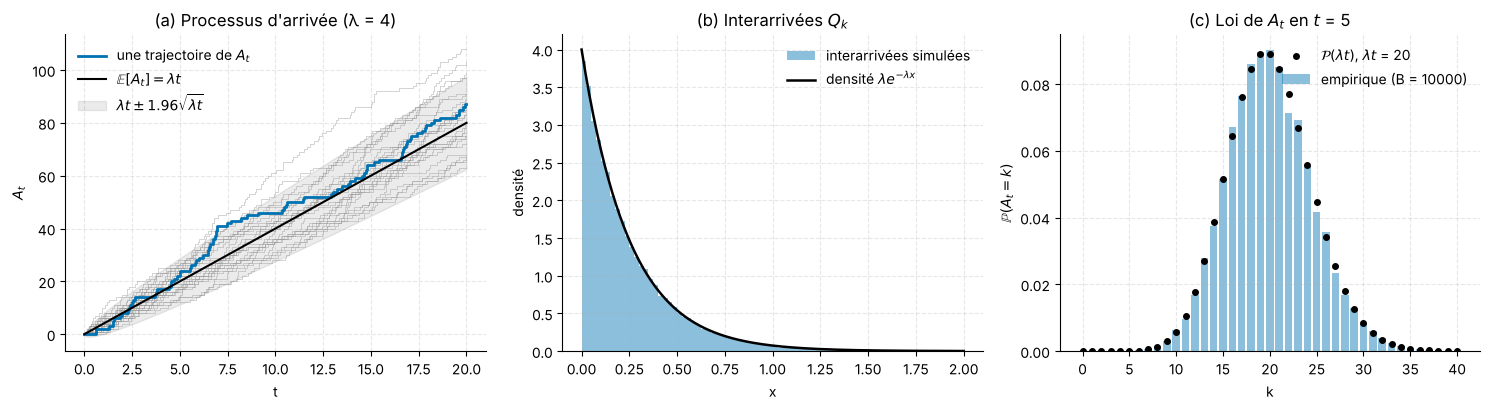

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) Trajectoires de A_t, moyenne λt et bande de fluctuation ponctuelle λt ± 1.96 sqrt(λt)
ax = axs[0]
t_line = np.linspace(0, T_max, 400)
for _ in range(25):
    Tb = simulate_arrivals(lam, T_max, rng)
    ax.step(np.r_[0, Tb, T_max], np.r_[0, np.arange(1, Tb.size + 1), Tb.size],
            where="post", color=C_GREY, lw=0.6, alpha=0.5)
ax.step(np.r_[0, T, T_max], np.r_[0, np.arange(1, T.size + 1), T.size],
        where="post", color=C_ARR, lw=2, label=r"une trajectoire de $A_t$")
ax.plot(t_line, lam * t_line, color=C_THEO, lw=1.5, label=r"$\mathbb{E}[A_t]=\lambda t$")
ax.fill_between(t_line, lam * t_line - 1.96 * np.sqrt(lam * t_line),
                lam * t_line + 1.96 * np.sqrt(lam * t_line), color=C_THEO, alpha=0.08,
                label=r"$\lambda t \pm 1.96\sqrt{\lambda t}$")
ax.set(title=f"(a) Processus d'arrivée (λ = {lam:g})", xlabel="t", ylabel=r"$A_t$")
ax.legend(loc="upper left")

# (b) Loi des interarrivées
ax = axs[1]
x = np.linspace(0, 2.0, 300)
ax.hist(Q_big, bins=80, range=(0, 2.0), density=True, color=C_ARR, alpha=0.45, label="interarrivées simulées")
ax.plot(x, lam * np.exp(-lam * x), color=C_THEO, lw=1.8, label=r"densité $\lambda e^{-\lambda x}$")
ax.set(title="(b) Interarrivées $Q_k$", xlabel="x", ylabel="densité")
ax.legend()

# (c) Loi de A_t0 : empirique vs Poisson(λ t0)
ax = axs[2]
k = np.arange(0, 41)
emp = np.bincount(A_t0, minlength=k.size)[:k.size] / B_arr
ax.bar(k, emp, width=0.8, color=C_ARR, alpha=0.45, label=f"empirique (B = {B_arr})")
ax.plot(k, stats.poisson.pmf(k, lam * t0), "o", color=C_THEO, ms=4, label=fr"$\mathcal{{P}}(\lambda t)$, $\lambda t$ = {lam*t0:g}")
ax.set(title=fr"(c) Loi de $A_t$ en $t$ = {t0:g}", xlabel="k", ylabel=r"$\mathbb{P}(A_t=k)$")
ax.legend()

plt.tight_layout()
plt.show()

**Commentaires.**
- La trajectoire de $A_t$ est une fonction en escalier croissante, de sauts unité, qui suit la droite $\lambda t$ : c'est la loi des grands nombres $A_t/t\to\lambda$.
- Les fluctuations autour de $\lambda t$ sont d'ordre $\sqrt{\lambda t}$ (TCL : $(A_t-\lambda t)/\sqrt{\lambda t}\Rightarrow\mathcal N(0,1)$) : l'écart absolu grandit, l'écart relatif diminue.
- L'histogramme des interarrivées épouse la densité exponentielle (test KS non rejeté), et la loi de $A_t$ à $t$ fixé coïncide avec la loi de Poisson $\mathcal P(\lambda t)$ : moyenne et variance empiriques sont toutes deux proches de $\lambda t$ (test du $\chi^2$ non rejeté).

## Question I.2 — Temps de service, départs et processus $N_t$

*Énoncé.* Générer les temps de service $S_k\sim\mathrm{Exp}(\mu)$, en déduire $B_n$, $D_n$, $W_{q,n}$, $W_n$ puis le processus $N_t=A_t-D_t$. Tracer.

*Correction.* La récurrence $B_n=\max(T_n,D_{n-1})$, $D_n=B_n+S_n$ est séquentielle : une boucle est naturelle (on la fait sur des listes Python, nettement plus rapides que l'indexation scalaire de tableaux NumPy). Pour le tracé, on évalue $N_t$ exactement aux instants d'événements (arrivées et départs), où se produisent ses seuls sauts.

In [7]:
def simulate_mm1(lam, mu, T_max, rng):
    """Simule une file M/M/1 FIFO, initialement vide, pour les clients arrivés dans [0, T_max]."""
    T = simulate_arrivals(lam, T_max, rng)
    S = rng.exponential(scale=1 / mu, size=T.size)
    B, D = np.empty(T.size), np.empty(T.size)
    last_departure = 0.0
    for k, (t, s) in enumerate(zip(T.tolist(), S.tolist())):
        b = t if t > last_departure else last_departure   # B_n = max(T_n, D_{n-1})
        last_departure = b + s                              # D_n = B_n + S_n
        B[k], D[k] = b, last_departure
    return {"T": T, "S": S, "B": B, "D": D, "Wq": B - T, "W": D - T}


def N_process(t, T, D):
    """N_t = A_t - D_t = #{n : T_n <= t < D_n}, vectorisé en t."""
    return counting_process(t, T) - counting_process(t, np.sort(D))


def step_path(T, D, t_end):
    """Trajectoire exacte (instants de saut, valeurs) de N_t sur [0, t_end]."""
    ev = np.sort(np.concatenate(([0.0], T[T <= t_end], D[D <= t_end])))
    return np.append(ev, t_end), np.append(N_process(ev, T, D), N_process(t_end, T, D))

In [8]:
lam, mu, T_max = 4.0, 5.0, 20.0
rng = np.random.default_rng(SEED)
r = simulate_mm1(lam, mu, T_max, rng)
T, S, Bn, D = r["T"], r["S"], r["B"], r["D"]

# Vérifications de cohérence
assert np.all(np.diff(D) > 0), "les départs doivent être croissants (FIFO, 1 serveur)"
assert np.all(Bn >= T) and np.all(Bn[1:] >= D[:-1] - 1e-12)
assert np.allclose(D - T, r["Wq"] + S)
print(f"{T.size} clients arrivés sur [0, {T_max:g}] ; départs croissants : {np.all(np.diff(D) > 0)}")
print(f"Taux d'occupation empirique du serveur ≈ {S[D <= T_max].sum() / T_max:.3f}   (ρ = {lam/mu:.2f})\n")

print(f"{'n':>3} {'T_n':>8} {'S_n':>8} {'B_n':>8} {'D_n':>8} {'Wq_n':>8} {'W_n':>8}")
for k in range(8):
    print(f"{k+1:>3} {T[k]:8.3f} {S[k]:8.3f} {Bn[k]:8.3f} {D[k]:8.3f} {r['Wq'][k]:8.3f} {r['W'][k]:8.3f}")

87 clients arrivés sur [0, 20] ; départs croissants : True
Taux d'occupation empirique du serveur ≈ 0.679   (ρ = 0.80)

  n      T_n      S_n      B_n      D_n     Wq_n      W_n
  1    0.584    0.259    0.584    0.843    0.000    0.259
  2    0.609    0.048    0.843    0.891    0.234    0.282
  3    1.281    0.037    1.281    1.318    0.000    0.037
  4    1.494    0.365    1.494    1.859    0.000    0.365
  5    1.507    0.268    1.859    2.127    0.352    0.620
  6    1.559    0.132    2.127    2.259    0.568    0.700
  7    1.844    0.112    2.259    2.371    0.415    0.527
  8    1.985    0.048    2.371    2.419    0.386    0.434


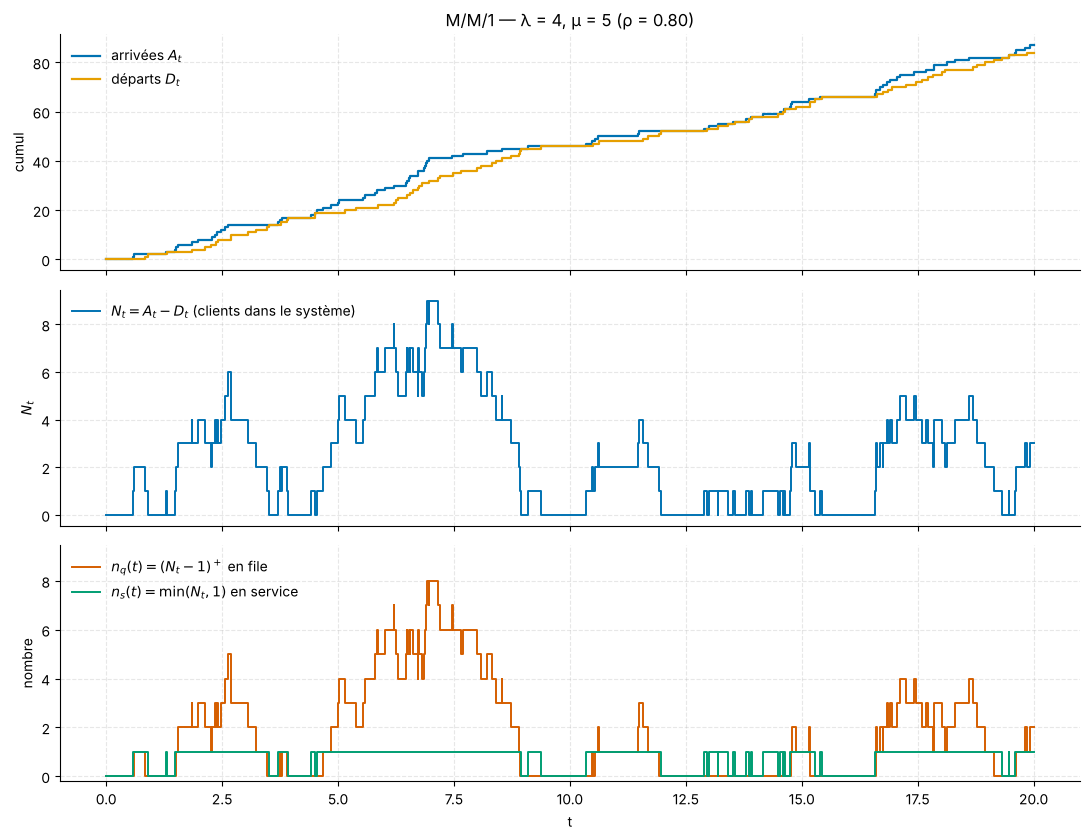

In [9]:
tt, NN = step_path(T, D, T_max)
nA = counting_process(tt, T)
nD = counting_process(tt, D)

fig, axs = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)

ax = axs[0]
ax.step(tt, nA, where="post", color=C_ARR, lw=1.6, label=r"arrivées $A_t$")
ax.step(tt, nD, where="post", color=C_DEP, lw=1.6, label=r"départs $D_t$")
ax.set(ylabel="cumul", title=fr"M/M/1 — λ = {lam:g}, μ = {mu:g} (ρ = {lam/mu:.2f})")
ax.legend(loc="upper left")

ax = axs[1]
ax.step(tt, NN, where="post", color=C_ARR, lw=1.4, label=r"$N_t=A_t-D_t$ (clients dans le système)")
ax.set(ylabel=r"$N_t$")
ax.legend(loc="upper left")

ax = axs[2]
ax.step(tt, np.maximum(NN - 1, 0), where="post", color=C_QUEUE, lw=1.4, label=r"$n_q(t)=(N_t-1)^+$ en file")
ax.step(tt, np.minimum(NN, 1), where="post", color=C_SERV, lw=1.4, label=r"$n_s(t)=\min(N_t,1)$ en service")
ax.set(ylabel="nombre", xlabel="t", ylim=(-0.2, axs[1].get_ylim()[1]))
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

**Commentaires.**
- $D_t$ reste toujours sous $A_t$ : l'écart **vertical** entre les deux escaliers est $N_t$, l'écart **horizontal** au niveau $n$ est le temps de séjour $W_n$ du $n$-ième client (FIFO).
- $N_t$ est en escalier avec des sauts $+1$ aux $T_n$ et $-1$ aux $D_n$ uniquement ; $n_s(t)\in\{0,1\}$ vaut 0 exactement pendant les périodes d'inactivité du serveur.
- La fraction du temps où le serveur est occupé est proche de $\rho$ (ici sur un horizon court, donc approximativement).

## Question I.3 — Influence de $\lambda$ et $\mu$

*Énoncé.* Constater l'effet des valeurs de $\lambda$ et $\mu$ sur le comportement du système.

*Correction.* Tout dépend du rapport $\rho=\lambda/\mu$ (à changement d'échelle de temps près). On compare quatre régimes à $\mu=5$ fixé : $\rho=0.4$, $0.8$, $0.95$ et $1.2$ (instable). Pour estimer $L$ sur une trajectoire, on utilise la **moyenne temporelle** $\frac{1}{t_1-t_0}\int_{t_0}^{t_1}N_s\,ds$, calculée exactement à partir de la **mesure d'occupation** (temps passé dans chaque état), après une période de chauffe $[0,t_0]$.

In [10]:
def occupation_measure(T, D, t0, t1):
    """Fraction du temps passé dans chaque état n sur [t0, t1] (calcul exact sur les événements)."""
    Ds = np.sort(D)
    ev = np.sort(np.concatenate(([t0], T[(T > t0) & (T < t1)], Ds[(Ds > t0) & (Ds < t1)], [t1])))
    N_left = counting_process(ev[:-1], T) - counting_process(ev[:-1], Ds)  # valeur sur [ev_i, ev_{i+1})
    return np.bincount(N_left, weights=np.diff(ev)) / (t1 - t0)

    ρ   L théo  L simulé   W théo  W simulé  max N_t
 0.40     0.67      0.82     0.33      0.37        9
 0.80     4.00      3.45     1.00      0.85       17
 0.95    19.00     11.71     4.00      2.50       34
 1.20        ∞     91.80        ∞     18.02      148


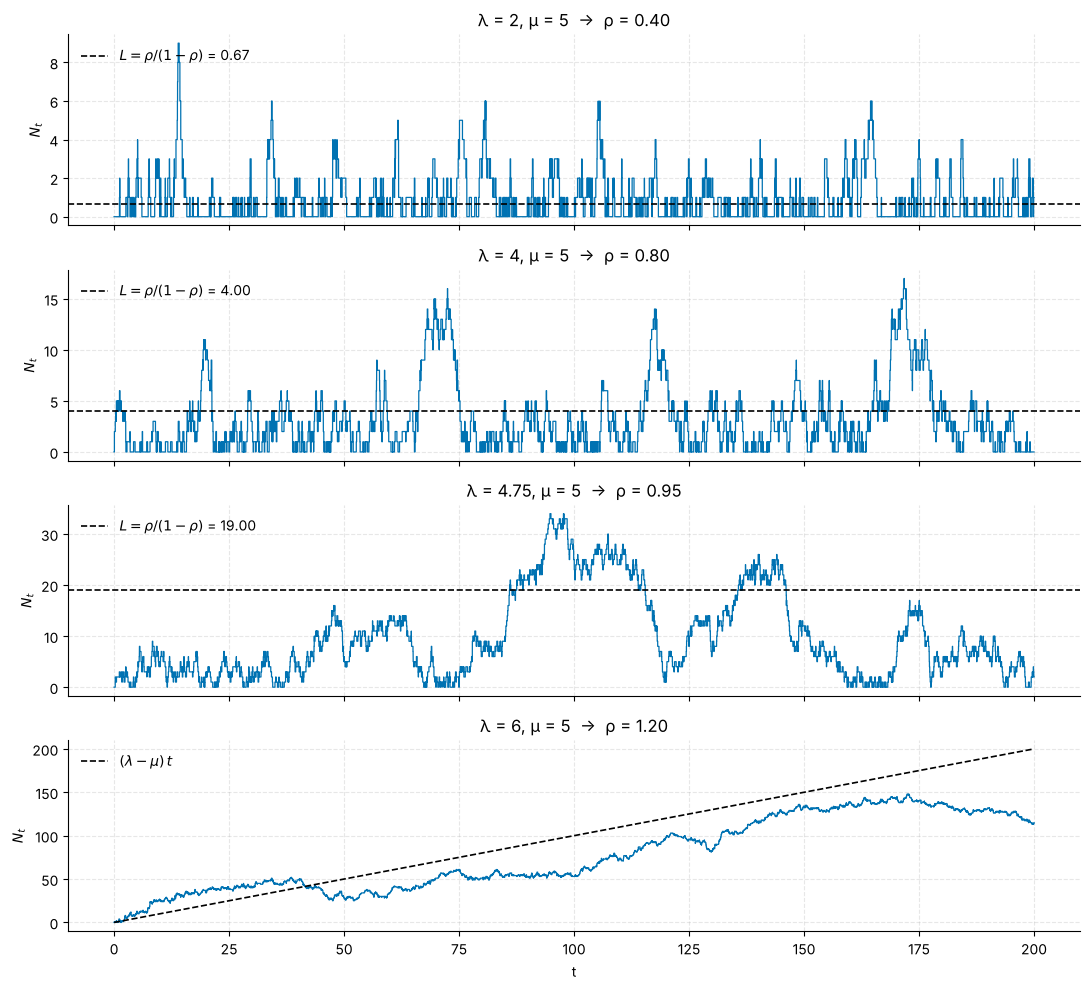

In [11]:
mu, T_max, t_burn = 5.0, 200.0, 50.0
scenarios = [2.0, 4.0, 4.75, 6.0]          # rho = 0.4, 0.8, 0.95, 1.2

fig, axs = plt.subplots(len(scenarios), 1, figsize=(11, 10), sharex=True)
print(f"{'ρ':>5} {'L théo':>8} {'L simulé':>9} {'W théo':>8} {'W simulé':>9} {'max N_t':>8}")
for i, lam_i in enumerate(scenarios):
    rho = lam_i / mu
    r_i = simulate_mm1(lam_i, mu, T_max, np.random.default_rng(SEED + i))
    tt, NN = step_path(r_i["T"], r_i["D"], T_max)
    occ = occupation_measure(r_i["T"], r_i["D"], t_burn, T_max)
    L_sim = occ @ np.arange(occ.size)
    W_sim = r_i["W"][r_i["T"] >= t_burn].mean()
    ax = axs[i]
    ax.step(tt, NN, where="post", color=C_ARR, lw=0.9)
    if rho < 1:
        th = mm1_metrics(lam_i, mu)
        ax.axhline(th["L"], color=C_THEO, ls="--", lw=1.2, label=fr"$L=\rho/(1-\rho)$ = {th['L']:.2f}")
        print(f"{rho:5.2f} {th['L']:8.2f} {L_sim:9.2f} {th['W']:8.2f} {W_sim:9.2f} {NN.max():8d}")
    else:
        ax.plot(tt, (lam_i - mu) * tt, color=C_THEO, ls="--", lw=1.2, label=r"$(\lambda-\mu)\,t$")
        print(f"{rho:5.2f} {'∞':>8} {L_sim:9.2f} {'∞':>8} {W_sim:9.2f} {NN.max():8d}")
    ax.set(ylabel=r"$N_t$", title=fr"λ = {lam_i:g}, μ = {mu:g}  →  ρ = {rho:.2f}")
    ax.legend(loc="upper left")
axs[-1].set_xlabel("t")
plt.tight_layout()
plt.show()

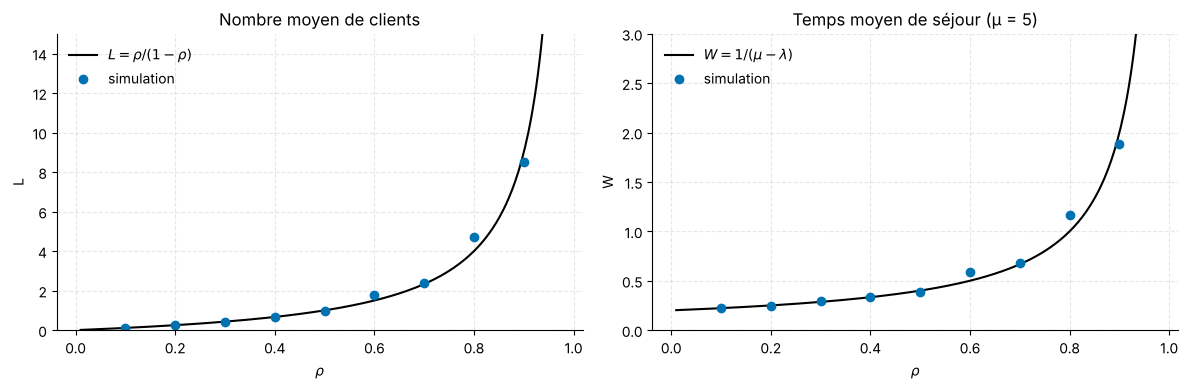

In [12]:
# L(ρ) et W(ρ) : théorie vs simulation longue (une trajectoire par point, horizon 5000, chauffe 500)
mu = 5.0
rho_th = np.linspace(0.01, 0.97, 300)
rho_sim = np.arange(0.1, 0.95, 0.1)
L_sim, W_sim = [], []
for j, rho in enumerate(rho_sim):
    r_j = simulate_mm1(rho * mu, mu, 5000.0, np.random.default_rng(SEED + 100 + j))
    occ = occupation_measure(r_j["T"], r_j["D"], 500.0, 5000.0)
    L_sim.append(occ @ np.arange(occ.size))
    W_sim.append(r_j["W"][r_j["T"] >= 500.0].mean())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(rho_th, rho_th / (1 - rho_th), color=C_THEO, label=r"$L=\rho/(1-\rho)$")
axs[0].plot(rho_sim, L_sim, "o", color=C_ARR, label="simulation")
axs[0].set(ylim=(0, 15), xlabel=r"$\rho$", ylabel="L", title="Nombre moyen de clients")
axs[1].plot(rho_th, 1 / (mu * (1 - rho_th)), color=C_THEO, label=r"$W=1/(\mu-\lambda)$")
axs[1].plot(rho_sim, W_sim, "o", color=C_ARR, label="simulation")
axs[1].set(ylim=(0, 3), xlabel=r"$\rho$", ylabel="W", title=fr"Temps moyen de séjour (μ = {mu:g})")
for ax in axs:
    ax.legend()
plt.tight_layout()
plt.show()

**Commentaires.**
- **$\rho$ petit** ($0.4$) : le serveur est souvent libre, $N_t$ reste proche de 0 et revient très vite à 0.
- **$\rho\to1^-$** ($0.8$ puis $0.95$) : longues excursions, files ponctuellement très longues. $L$ et $W$ explosent en $1/(1-\rho)$ — à $\rho=0.95$, $L=19$ alors que le serveur n'est « que » 5 % sous la saturation. Les fluctuations deviennent énormes et le système met très longtemps à « oublier » son état initial : une simulation de longueur fixée estime alors $L$ beaucoup moins bien, ce que montrent les écarts du tableau.
- **$\rho>1$** : il n'y a pas de régime stationnaire, $N_t$ croît linéairement à la vitesse $\lambda-\mu$ ; la « moyenne » simulée ne dépend que de l'horizon choisi et n'a pas de sens.
- À $\rho$ fixé, multiplier $\lambda$ et $\mu$ par une même constante ne change pas la loi de $N$ (même $L$) mais divise les temps ($W$, $W_q$) par cette constante.

## Question I.4 — Étude Monte Carlo ($B=1000$ réplications)

*Énoncé.* Simuler $B$ trajectoires indépendantes ; tracer la trajectoire moyenne avec une région de confiance empirique ; estimer la longueur moyenne de file et le temps moyen dans le système avec leurs écarts-types ; comparer aux valeurs théoriques.

### Méthodologie et justification des intervalles

On fixe $\lambda=4$, $\mu=5$ ($\rho=0.8$, $L=4$, $W=1$). Pour $b=1,\dots,B$ on simule une trajectoire indépendante sur $[0,T_{\max}]$, $T_{\max}=300$, partant du système vide.

1. **Trajectoire moyenne.** En chaque $t$ d'une grille, $\bar N(t)=\frac1B\sum_b N^{(b)}_t$ estime $m(t)=\mathbb E[N_t]$. Les $N^{(b)}_t$ sont i.i.d. de variance finie (à $t$ fixé, $N_t\le A_t$ qui est de Poisson), donc par le **TCL**
$$\frac{\bar N(t)-m(t)}{s(t)/\sqrt B}\;\xrightarrow{\;\mathcal L\;}\;\mathcal N(0,1),$$
d'où l'IC ponctuel à 95 % : $\bar N(t)\pm t_{B-1,0.975}\,s(t)/\sqrt B$. Avec $B=1000$, $t_{999,0.975}=1.962\approx z_{0.975}=1.960$ : Student et loi normale sont équivalents (Student est simplement le choix conservateur ; il n'est pas « exact » ici car $N_t$ n'est pas gaussien).
2. **À ne pas confondre** : cet IC porte sur l'**espérance** et rétrécit en $1/\sqrt B$. La **dispersion des trajectoires** elle-même ne diminue pas avec $B$ ; on la représente par la bande des **quantiles empiriques** 5 %–95 % de $N_t$ (une bande $\bar N\pm1.96\,s$ serait fausse : $N_t$ est discret, positif et asymétrique).
3. **Grandeurs stationnaires.** Sur chaque réplication, après une période de chauffe $t_0=100$ (on vérifie plus bas, sur les histogrammes, que la loi de $N_t$ est alors stationnaire), on calcule
$\hat L^{(b)}=\frac{1}{T_{\max}-t_0}\int_{t_0}^{T_{\max}}N_s\,ds$, $\hat L_q^{(b)}$ (idem avec $(N_s-1)^+$), et $\hat W^{(b)}$, $\hat W_q^{(b)}$ : moyennes sur les clients arrivés après $t_0$. Les $\hat L^{(b)}$ sont i.i.d. (une valeur par réplication indépendante), ce qui rend légitime l'IC de Student ci-dessus — alors que les $W_n$ d'une **même** trajectoire sont fortement corrélés et ne le permettraient pas.
4. **Deux écarts-types différents** : l'écart-type **entre réplications** de $\hat L^{(b)}$ (précision de l'estimateur, liée à la durée de la fenêtre) et l'écart-type **intrinsèque** de $N$ ou de $W$ en régime stationnaire (dispersion du phénomène : $\sigma_N=\sqrt\rho/(1-\rho)$, $\sigma_W=1/(\mu-\lambda)$).

In [13]:
lam, mu = 4.0, 5.0
B = 1000
T_max, t_burn = 300.0, 100.0
t_grid = np.linspace(0, 100, 401)                 # grille (équidistante, part de 0) pour la trajectoire moyenne
th = mm1_metrics(lam, mu)

rng = np.random.default_rng(SEED)
N_grid = np.empty((B, t_grid.size), dtype=int)
L_hat, Lq_hat, W_hat, Wq_hat, lam_hat, varN_hat = (np.empty(B) for _ in range(6))
W_iid = np.empty(B)                               # client n° 600 de chaque réplication -> échantillon i.i.d.
W_pool, Wq_pool = [], []
for b in range(B):
    r_b = simulate_mm1(lam, mu, T_max, rng)
    T_b, D_b = r_b["T"], r_b["D"]
    N_grid[b] = N_process(t_grid, T_b, D_b)
    occ = occupation_measure(T_b, D_b, t_burn, T_max)
    n = np.arange(occ.size)
    L_hat[b] = occ @ n
    Lq_hat[b] = occ @ np.maximum(n - 1, 0)
    varN_hat[b] = occ @ n**2 - L_hat[b]**2
    win = T_b >= t_burn                           # clients arrivés en régime stationnaire
    W_hat[b], Wq_hat[b] = r_b["W"][win].mean(), r_b["Wq"][win].mean()
    lam_hat[b] = win.sum() / (T_max - t_burn)
    W_iid[b] = r_b["W"][600]                      # arrivé vers t ≈ 150, donc en régime stationnaire
    W_pool.append(r_b["W"][win])
    Wq_pool.append(r_b["Wq"][win])
W_pool, Wq_pool = np.concatenate(W_pool), np.concatenate(Wq_pool)
print(f"{B} réplications simulées, {W_pool.size:,} clients en régime stationnaire au total.")

1000 réplications simulées, 799,816 clients en régime stationnaire au total.


Quantile de Student t_(999; 0.975) = 1.9623  (normale : 1.9600)
Part des instants de la grille où E[N_t] théorique est dans l'IC 95 % : 99.8%


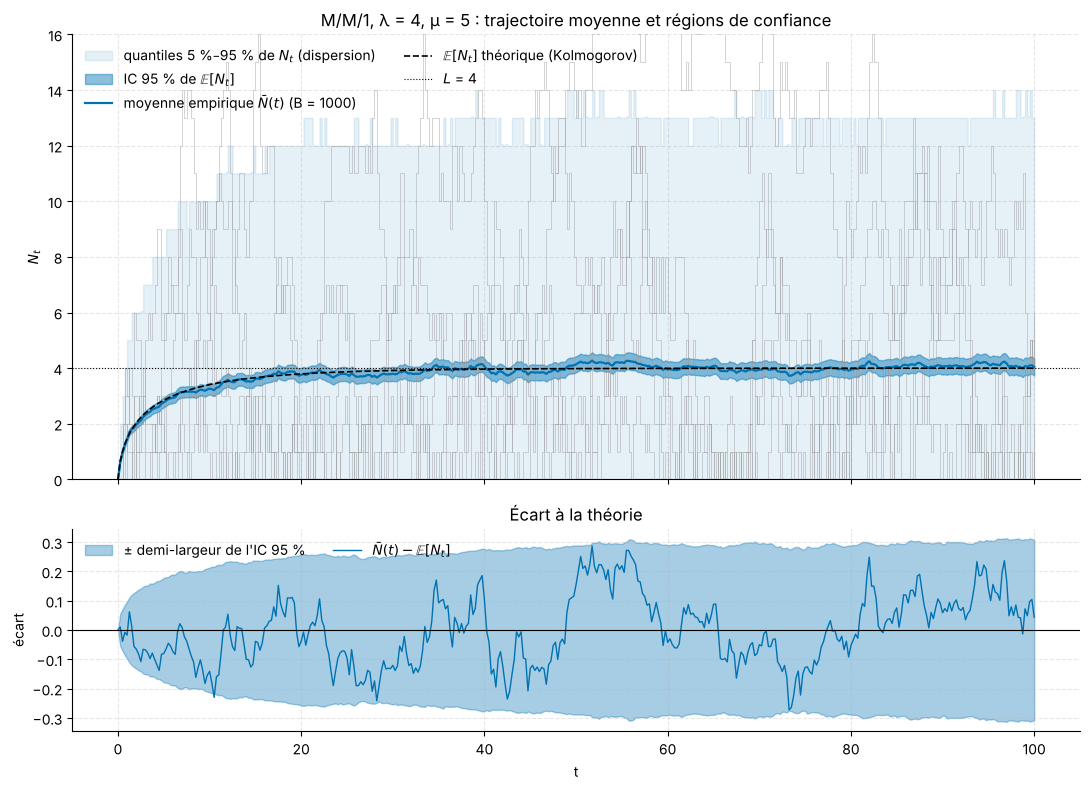

In [14]:
# Loi transitoire théorique exacte (espace tronqué à n_max = 200, système vide à t = 0)
n_max = 200
birth = np.full(n_max + 1, lam); birth[-1] = 0.0
death = np.full(n_max + 1, mu);  death[0] = 0.0
p0 = np.zeros(n_max + 1); p0[0] = 1.0
P_theo = bd_transient(birth, death, p0, t_grid)          # P_theo[i, n] = P(N_{t_i} = n)
m_theo = P_theo @ np.arange(n_max + 1)

# Statistiques Monte Carlo ponctuelles
m_hat = N_grid.mean(axis=0)
s_hat = N_grid.std(axis=0, ddof=1)
h = stats.t.ppf(0.975, B - 1) * s_hat / np.sqrt(B)
q05, q95 = np.quantile(N_grid, [0.05, 0.95], axis=0)
inside = np.mean(np.abs(m_hat - m_theo) <= h)
print(f"Quantile de Student t_(999; 0.975) = {stats.t.ppf(0.975, B - 1):.4f}  (normale : 1.9600)")
print(f"Part des instants de la grille où E[N_t] théorique est dans l'IC 95 % : {inside:.1%}")

fig, axs = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axs[0]
for b in range(5):
    ax.step(t_grid, N_grid[b], where="post", color=C_GREY, lw=0.5, alpha=0.6)
ax.fill_between(t_grid, q05, q95, step="post", color=C_ARR, alpha=0.10, label="quantiles 5 %–95 % de $N_t$ (dispersion)")
ax.fill_between(t_grid, m_hat - h, m_hat + h, color=C_ARR, alpha=0.45, label=r"IC 95 % de $\mathbb{E}[N_t]$")
ax.plot(t_grid, m_hat, color=C_ARR, lw=1.6, label=fr"moyenne empirique $\bar N(t)$ (B = {B})")
ax.plot(t_grid, m_theo, color=C_THEO, lw=1.2, ls="--", label=r"$\mathbb{E}[N_t]$ théorique (Kolmogorov)")
ax.axhline(th["L"], color=C_THEO, lw=0.8, ls=":", label=fr"$L$ = {th['L']:.0f}")
ax.set(ylabel=r"$N_t$", ylim=(0, 16),
       title=fr"M/M/1, λ = {lam:g}, μ = {mu:g} : trajectoire moyenne et régions de confiance")
ax.legend(loc="upper left", ncol=2)

ax = axs[1]
ax.fill_between(t_grid, -h, h, color=C_ARR, alpha=0.35, label="± demi-largeur de l'IC 95 %")
ax.plot(t_grid, m_hat - m_theo, color=C_ARR, lw=1.0, label=r"$\bar N(t)-\mathbb{E}[N_t]$")
ax.axhline(0, color=C_THEO, lw=0.8)
ax.set(xlabel="t", ylabel="écart", title="Écart à la théorie")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

In [15]:
def print_table(rows):
    print(f"{'Grandeur':<10} {'moyenne MC':>11} {'écart-type':>11} {'IC 95 %':>21} {'théorie':>9} {'dans IC':>8}")
    print("-" * 75)
    for name, x, theo in rows:
        m, s, lo, hi = mc_summary(x)
        print(f"{name:<10} {m:11.4f} {s:11.4f}   [{lo:8.4f}, {hi:8.4f}] {theo:9.4f} {'oui' if lo <= theo <= hi else 'NON':>8}")

print("Estimateurs stationnaires (une valeur par réplication, écart-type entre réplications) :\n")
print_table([("L", L_hat, th["L"]), ("Lq", Lq_hat, th["Lq"]),
             ("W", W_hat, th["W"]), ("Wq", Wq_hat, th["Wq"])])

print("\nDispersion intrinsèque en régime stationnaire :")
print(f"  écart-type de N : {np.sqrt(varN_hat.mean()):.3f}   (théorie √ρ/(1-ρ) = {np.sqrt(th['rho'])/(1-th['rho']):.3f})")
print(f"  écart-type de W : {W_pool.std(ddof=1):.3f}   (théorie 1/(μ-λ)   = {1/(mu-lam):.3f})")

print("\nLoi de Little :")
print(f"  moyenne de L̂            = {L_hat.mean():.4f}")
print(f"  moyenne de λ̂ · Ŵ        = {(lam_hat * W_hat).mean():.4f}")
print(f"  théorie λ W              = {lam * th['W']:.4f}")
print(f"\nP(Wq = 0) (client servi sans attendre) : {np.mean(Wq_pool == 0):.4f}   (théorie 1 - ρ = {1 - th['rho']:.4f})")

Estimateurs stationnaires (une valeur par réplication, écart-type entre réplications) :

Grandeur    moyenne MC  écart-type               IC 95 %   théorie  dans IC
---------------------------------------------------------------------------
L               4.0349      1.3475   [  3.9512,   4.1185]    4.0000      oui
Lq              3.2341      1.3190   [  3.1523,   3.3160]    3.2000      oui
W               1.0038      0.3134   [  0.9843,   1.0232]    1.0000      oui
Wq              0.8035      0.3096   [  0.7843,   0.8228]    0.8000      oui

Dispersion intrinsèque en régime stationnaire :
  écart-type de N : 4.365   (théorie √ρ/(1-ρ) = 4.472)
  écart-type de W : 1.022   (théorie 1/(μ-λ)   = 1.000)

Loi de Little :
  moyenne de L̂            = 4.0349
  moyenne de λ̂ · Ŵ        = 4.0326
  théorie λ W              = 4.0000

P(Wq = 0) (client servi sans attendre) : 0.1991   (théorie 1 - ρ = 0.2000)


**Commentaires.**
- Partant du système vide, $\bar N(t)$ croît puis se stabilise autour de $L=4$ ; la courbe théorique $\mathbb E[N_t]$ obtenue par les équations de Kolmogorov reste dans l'IC à 95 % sur l'essentiel de la grille (la proportion attendue est d'environ 95 %, avec des instants voisins fortement corrélés).
- La bande d'IC est étroite (largeur $\propto 1/\sqrt B$) alors que la bande des quantiles 5 %–95 % reste large : la **moyenne** est bien estimée, mais une **trajectoire** individuelle s'en écarte beaucoup.
- Les quatre estimateurs $L$, $L_q$, $W$, $W_q$ sont compatibles avec la théorie ; l'écart-type entre réplications mesure la précision obtenue avec une fenêtre de 200 unités de temps (il diminuerait en $1/\sqrt{T_{\max}-t_0}$).
- La loi de Little est vérifiée empiriquement, de même que $\mathbb P(W_q=0)=1-\rho$ : une fraction $1-\rho$ des clients trouve le serveur libre (conséquence de PASTA).
- La dispersion intrinsèque est grande : $\sigma_N\approx 4.5$ pour une moyenne de 4, et $\sigma_W=\mathbb E[W]$ (loi exponentielle).

### Loi des états : régime transitoire

À chaque instant $t$ fixé, les $B$ valeurs $N^{(1)}_t,\dots,N^{(B)}_t$ forment un échantillon i.i.d. de la loi $p(t)=(p_n(t))_n$. On compare leur histogramme à la loi théorique $p(t)=\delta_0\,e^{tQ}$ et, pour référence, à la loi stationnaire $\pi$.

    t  TV(emp, p(t))  TV(p(t), π)  χ² p-valeur
    1         0.0314       0.2965        0.447
    3         0.0336       0.1517        0.877
    8         0.0457       0.0576        0.146
   20         0.0563       0.0129        0.466
   50         0.0546       0.0009        0.423
  100         0.0579       0.0000        0.287


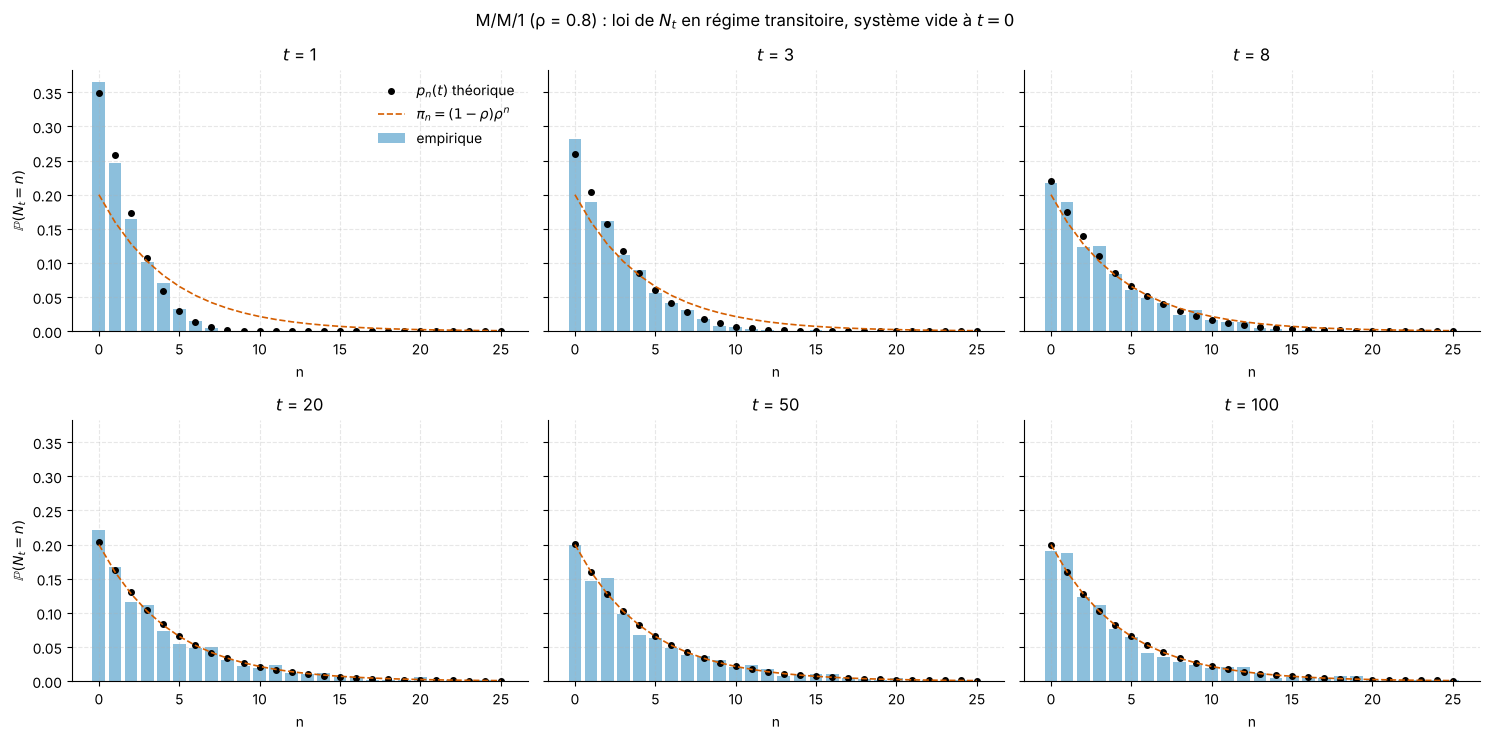

In [16]:
pi = mm1_stationary(lam, mu, n_max)
t_show = [1, 3, 8, 20, 50, 100]
n_plot = np.arange(0, 26)

fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
print(f"{'t':>5} {'TV(emp, p(t))':>14} {'TV(p(t), π)':>12} {'χ² p-valeur':>12}")
for ax, t_s in zip(axs.ravel(), t_show):
    i = np.argmin(np.abs(t_grid - t_s))
    sample = N_grid[:, i]
    emp = np.bincount(sample, minlength=n_max + 1)[:n_max + 1] / B
    ax.bar(n_plot, emp[:n_plot.size], width=0.8, color=C_ARR, alpha=0.45, label="empirique")
    ax.plot(n_plot, P_theo[i, :n_plot.size], "o", color=C_THEO, ms=4, label=r"$p_n(t)$ théorique")
    ax.plot(n_plot, pi[:n_plot.size], "--", color=C_QUEUE, lw=1.2, label=r"$\pi_n=(1-\rho)\rho^n$")
    _, pval, _ = chi2_gof(sample, P_theo[i])
    print(f"{t_s:5g} {total_variation(emp, P_theo[i]):14.4f} {total_variation(P_theo[i], pi):12.4f} {pval:12.3f}")
    ax.set(title=fr"$t$ = {t_grid[i]:g}", xlabel="n")
for ax in axs[:, 0]:
    ax.set_ylabel(r"$\mathbb{P}(N_t=n)$")
axs[0, 0].legend()
plt.suptitle(fr"M/M/1 (ρ = {lam/mu:.1f}) : loi de $N_t$ en régime transitoire, système vide à $t=0$", fontsize=12)
plt.tight_layout()
plt.show()

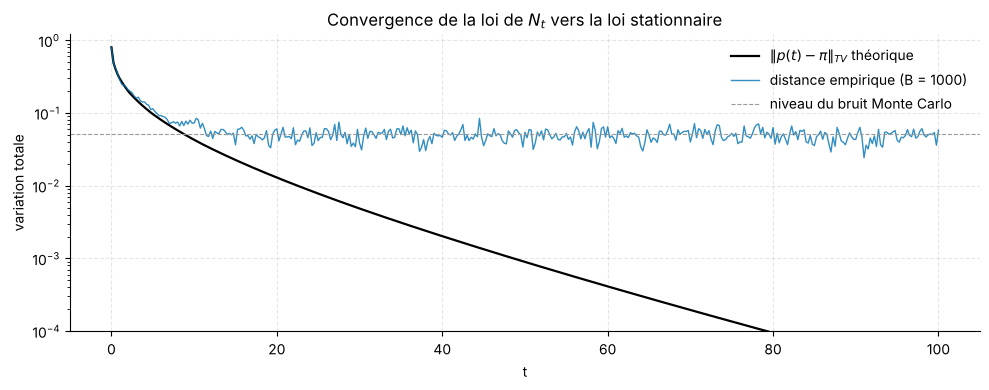

In [17]:
# Convergence vers le régime stationnaire : distance en variation totale entre p(t) et π
tv_theo = np.array([total_variation(P_theo[i], pi) for i in range(t_grid.size)])
tv_emp = np.array([total_variation(np.bincount(N_grid[:, i], minlength=n_max + 1)[:n_max + 1] / B, pi)
                   for i in range(t_grid.size)])

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(t_grid, tv_theo, color=C_THEO, lw=1.6, label=r"$\|p(t)-\pi\|_{TV}$ théorique")
ax.semilogy(t_grid, tv_emp, color=C_ARR, lw=1.0, alpha=0.8, label="distance empirique (B = 1000)")
# Niveau de bruit : E||p_hat - π||_TV ≈ (1/2) Σ_n sqrt(2/(π B)) sqrt(π_n (1 - π_n))  (TCL sur chaque fréquence)
noise = 0.5 * np.sqrt(2 / (np.pi * B)) * np.sum(np.sqrt(pi * (1 - pi)))
ax.axhline(noise, color=C_GREY, ls="--", lw=0.8, label="niveau du bruit Monte Carlo")
ax.set(xlabel="t", ylabel="variation totale", ylim=(1e-4, 1.2),
       title="Convergence de la loi de $N_t$ vers la loi stationnaire")
ax.legend()
plt.tight_layout()
plt.show()

**Commentaires.**
- Aux petits temps, la loi de $N_t$ est concentrée près de 0 (le système part vide) et très loin de la loi géométrique ; elle s'étale ensuite progressivement.
- L'histogramme empirique colle à $p(t)$ **à chaque instant** (tests du $\chi^2$ non rejetés) : la simulation reproduit le régime transitoire, pas seulement le régime limite.
- La distance $\|p(t)-\pi\|_{TV}$ décroît vers 0 (exponentiellement vite : droite en échelle logarithmique). Une fois cette distance passée sous le bruit Monte Carlo (d'ordre $1/\sqrt B$), on ne peut plus distinguer empiriquement $p(t)$ de $\pi$ : vers $t\approx 50$–$100$, le régime est stationnaire « à la précision de la simulation près ». C'est ce qui justifie la chauffe $t_0=100$.

### Loi des états : régime stationnaire

Trois façons d'observer la loi stationnaire, qui doivent toutes redonner $\pi_n=(1-\rho)\rho^n$ :
1. **en espace** : loi de $N_t$ pour $t$ grand, sur $B$ réplications indépendantes ;
2. **en temps** (ergodicité) : fraction du temps passé dans l'état $n$ le long d'**une seule** trajectoire très longue, $\frac1t\int_0^t\mathbf 1\{N_s=n\}\,ds\to\pi_n$ ;
3. pour le temps de séjour : $W\sim\mathrm{Exp}(\mu-\lambda)$.

(1) N_t en t = 100 sur B réplications : test du χ² -> p-valeur = 0.287 (16 ddl)
(2) Occupation d'une trajectoire de durée 20 000 : TV(occupation, π) = 0.0138
    moyenne temporelle de N = 3.946  (L = 4.000)
(3) W ~ Exp(μ-λ), test KS sur le client n° 600 de chaque réplication (i.i.d.) : p-valeur = 0.794


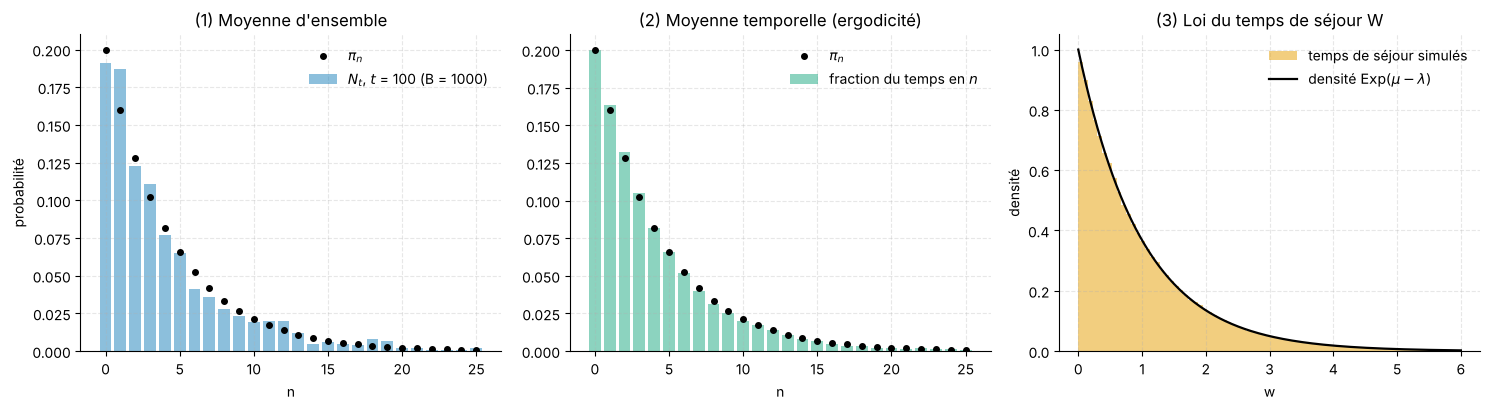

In [18]:
r_long = simulate_mm1(lam, mu, 20_000.0, np.random.default_rng(SEED + 7))
occ_long = occupation_measure(r_long["T"], r_long["D"], 0.0, 20_000.0)
sample_end = N_grid[:, -1]
emp_end = np.bincount(sample_end, minlength=n_max + 1)[:n_max + 1] / B

_, p_space, dof1 = chi2_gof(sample_end, pi)
ks_W = stats.kstest(W_iid, "expon", args=(0, 1 / (mu - lam)))
print(f"(1) N_t en t = {t_grid[-1]:g} sur B réplications : test du χ² -> p-valeur = {p_space:.3f} ({dof1} ddl)")
print(f"(2) Occupation d'une trajectoire de durée 20 000 : TV(occupation, π) = {total_variation(occ_long, pi):.4f}")
print(f"    moyenne temporelle de N = {occ_long @ np.arange(occ_long.size):.3f}  (L = {th['L']:.3f})")
print(f"(3) W ~ Exp(μ-λ), test KS sur le client n° 600 de chaque réplication (i.i.d.) : p-valeur = {ks_W.pvalue:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axs[0]
ax.bar(n_plot, emp_end[:n_plot.size], width=0.8, color=C_ARR, alpha=0.45, label=fr"$N_t$, $t$ = {t_grid[-1]:g} (B = {B})")
ax.plot(n_plot, pi[:n_plot.size], "o", color=C_THEO, ms=4, label=r"$\pi_n$")
ax.set(title="(1) Moyenne d'ensemble", xlabel="n", ylabel="probabilité"); ax.legend()

ax = axs[1]
ax.bar(n_plot, np.pad(occ_long, (0, 50))[:n_plot.size], width=0.8, color=C_SERV, alpha=0.45,
       label="fraction du temps en $n$")
ax.plot(n_plot, pi[:n_plot.size], "o", color=C_THEO, ms=4, label=r"$\pi_n$")
ax.set(title="(2) Moyenne temporelle (ergodicité)", xlabel="n"); ax.legend()

ax = axs[2]
x = np.linspace(0, 6, 300)
ax.hist(W_pool, bins=80, range=(0, 6), density=True, color=C_DEP, alpha=0.5, label="temps de séjour simulés")
ax.plot(x, (mu - lam) * np.exp(-(mu - lam) * x), color=C_THEO, lw=1.6, label=r"densité $\mathrm{Exp}(\mu-\lambda)$")
ax.set(title="(3) Loi du temps de séjour W", xlabel="w", ylabel="densité"); ax.legend()
plt.tight_layout()
plt.show()

**Commentaires.**
- Les trois approches redonnent la loi géométrique : moyenne d'ensemble à $t$ grand et moyenne temporelle le long d'une trajectoire coïncident (**ergodicité** de la chaîne positive récurrente quand $\rho<1$).
- Le temps de séjour est bien exponentiel de paramètre $\mu-\lambda$. Pour le test KS, on n'utilise qu'**un** client par réplication, le client n° 600 (indice fixé à l'avance) : les temps de séjour successifs d'une même trajectoire sont corrélés et invalideraient le test (l'histogramme, lui, peut utiliser tous les clients).
- **Piège classique** : prendre « le premier client arrivé après $t_0$ » donnerait un échantillon **biaisé** (temps de séjour trop courts). Par définition aucun client n'est arrivé entre $t_0$ et lui : le système n'a fait que se vider pendant cet intervalle, et ce client voit en moyenne moins de $L$ clients. PASTA porte sur les arrivées prises dans leur ensemble (ou d'indice fixé), pas sur une arrivée sélectionnée par un critère qui dépend de l'absence d'arrivées.

**Synthèse de la partie I.** File en attente, service, système :
$W=W_q+1/\mu$ — à $\rho=0.8$, un client passe en moyenne $0.8$ en file pour $0.2$ en service : l'attente domine dès que la charge est forte, et c'est elle qui explose quand $\rho\to1$, le temps de service restant fixé à $1/\mu$.

---
# Partie II — La file M/M/c/K

## Rappels théoriques

**Hypothèses.**
- Arrivées poissoniennes de taux $\lambda$ ; services i.i.d. $\mathrm{Exp}(\mu)$, indépendants des arrivées.
- $c$ **serveurs identiques** en parallèle, discipline FIFO (un client prend le premier serveur libre).
- **Capacité totale $K\ge c$** : au plus $c$ clients en service et $K-c$ en attente. Un client qui arrive quand $N=K$ est **refusé** et perdu (pas de rappel).

Cas particuliers : $c=1$ (M/M/1/K), $K=c$ (M/M/c/c, modèle d'Erlang « B », sans attente), $K=\infty$ (M/M/c, Erlang « C », stable si $\lambda<c\mu$).

**Processus $N_t$.** Processus de naissance-mort sur $\{0,\dots,K\}$ :
$$\lambda_n=\lambda\,\mathbf 1\{n<K\},\qquad \mu_n=\min(n,c)\,\mu .$$
Avec $n$ clients, $\min(n,c)$ serveurs travaillent : le taux de départ sature à $c\mu$ dès que $n\ge c$.

**Charges.** $a=\lambda/\mu$ (charge offerte, en Erlangs), $\rho=a/c=\lambda/(c\mu)$.

**Régime stationnaire.** L'espace d'états est fini et la chaîne irréductible : **la loi stationnaire existe toujours, quel que soit $\rho$** (même $\rho\ge1$). L'équilibre local $\lambda\,\pi_{n-1}=\min(n,c)\,\mu\,\pi_n$ donne
$$\pi_n=\begin{cases}\pi_0\,\dfrac{a^n}{n!}, & 0\le n\le c,\\[8pt] \pi_0\,\dfrac{a^c}{c!}\,\rho^{\,n-c}, & c\le n\le K,\end{cases}\qquad \pi_0=\Big(\sum_{n=0}^{c}\frac{a^n}{n!}+\frac{a^c}{c!}\sum_{n=c+1}^{K}\rho^{\,n-c}\Big)^{-1}.$$

### Probabilité de refus et taux de perte (point central de cette partie)

Un client est refusé s'il arrive quand le système est plein. Deux quantités *a priori* différentes :
- la **proportion du temps** où le système est plein : $\pi_K=\lim_{t\to\infty}\frac1t\int_0^t\mathbf 1\{N_s=K\}\,ds$ ;
- la **proportion des clients refusés** (taux de perte) : $P_B=\lim_{n\to\infty}\frac{\#\{\text{refus parmi les } n \text{ premières arrivées}\}}{n}$.

Comme les arrivées sont poissoniennes, elles « échantillonnent » le système au hasard (**PASTA** : *Poisson Arrivals See Time Averages*), donc
$$\boxed{P_B=\pi_K=\pi_0\,\frac{a^c}{c!}\,\rho^{\,K-c}}$$
(ce n'est plus vrai avec des arrivées non poissoniennes). Les flux se décomposent en
$$\lambda=\underbrace{\lambda(1-\pi_K)}_{\lambda_{\rm eff}\ \text{(clients servis)}}+\underbrace{\lambda\,\pi_K}_{\lambda_{\rm perte}\ \text{(clients perdus)}},\qquad \mathbb E[R_t]\underset{t\to\infty}{\sim}\lambda\,\pi_K\,t,$$
où $R_t$ est le nombre de refus sur $[0,t]$. En régime transitoire, un client arrivant à l'instant $t$ est refusé avec probabilité $p_K(t)=\mathbb P(N_t=K)$, d'où $\mathbb E[R_t]=\lambda\int_0^t p_K(s)\,ds$.

Formules fermées utiles :
- **M/M/1/K** ($c=1$) : $P_B=\dfrac{(1-\rho)\rho^K}{1-\rho^{K+1}}$ si $\rho\ne1$, et $P_B=\dfrac1{K+1}$ si $\rho=1$ ;
- **M/M/c/c** (Erlang B) : $P_B=\dfrac{a^c/c!}{\sum_{k=0}^c a^k/k!}$, calculée par la récurrence stable $B_0=1$, $B_k=\dfrac{aB_{k-1}}{k+aB_{k-1}}$ ;
- quand $\rho>1$ et $K\to\infty$ : $P_B\to1-1/\rho$ (le débit servi sature à $c\mu$, tout l'excédent est perdu).

**Autres indicateurs.**
- $L=\sum_n n\,\pi_n$, $\;L_q=\sum_n (n-c)^+\pi_n$.
- **Little avec le débit effectif** : $W=L/\lambda_{\rm eff}$, $W_q=L_q/\lambda_{\rm eff}$, et $W=W_q+1/\mu$.
- Nombre moyen de serveurs occupés : $\sum_n\min(n,c)\pi_n=\lambda_{\rm eff}/\mu$ ; taux d'occupation d'un serveur $\lambda_{\rm eff}/(c\mu)$.
- $\mathbb P(W_q=0\mid\text{accepté})=\sum_{n<c}\pi_n/(1-\pi_K)$.

**Régime transitoire.** Mêmes équations de Kolmogorov $p'(t)=p(t)Q$ ; ici l'espace est fini, donc $p(t)=p(0)e^{tQ}$ est **exact** (aucune troncature).

In [19]:
def mmck_stationary(lam, mu, c, K):
    """Loi stationnaire de M/M/c/K par la récurrence d'équilibre local pi_n = pi_{n-1} lam / (min(n,c) mu)."""
    w = np.ones(K + 1)
    for n in range(1, K + 1):
        w[n] = w[n - 1] * lam / (min(n, c) * mu)
    return w / w.sum()


def mmck_metrics(lam, mu, c, K):
    """Indicateurs stationnaires théoriques de M/M/c/K."""
    pi = mmck_stationary(lam, mu, c, K)
    n = np.arange(K + 1)
    PB = pi[K]
    lam_eff = lam * (1 - PB)
    L, Lq = n @ pi, np.maximum(n - c, 0) @ pi
    return {"a": lam / mu, "rho": lam / (c * mu), "PB": PB, "lam_eff": lam_eff,
            "L": L, "Lq": Lq, "W": L / lam_eff, "Wq": Lq / lam_eff,
            "busy": np.minimum(n, c) @ pi, "P_no_wait": pi[:c].sum() / (1 - PB)}


def mmck_rates(lam, mu, c, K):
    """Taux de naissance et de mort de N_t pour M/M/c/K."""
    n = np.arange(K + 1)
    birth = np.where(n < K, lam, 0.0)
    death = np.minimum(n, c) * mu
    return birth, death


# --- Vérifications sur les cas particuliers ---
def erlang_b(c, a):
    b = 1.0
    for k in range(1, c + 1):
        b = a * b / (k + a * b)
    return b

m1 = mmck_metrics(4.0, 5.0, 1, 300)
print("c = 1, K = 300  (≈ M/M/1)   :", {k: round(m1[k], 4) for k in ["L", "W", "Wq"]},
      "| M/M/1 :", {k: round(v, 4) for k, v in mm1_metrics(4.0, 5.0).items() if k in ["L", "W", "Wq"]})
print(f"K = c = 4, a = 3 (Erlang B) : P_B = {mmck_metrics(15.0, 5.0, 4, 4)['PB']:.6f} | formule d'Erlang B : {erlang_b(4, 3.0):.6f}")
m = mmck_metrics(12.0, 5.0, 3, 8)
print(f"Cohérence W = Wq + 1/μ  : {m['W']:.6f} = {m['Wq'] + 1/5:.6f} ;  serveurs occupés = λ_eff/μ : {m['busy']:.6f} = {m['lam_eff']/5:.6f}")

c = 1, K = 300  (≈ M/M/1)   : {'L': np.float64(4.0), 'W': np.float64(1.0), 'Wq': np.float64(0.8)} | M/M/1 : {'L': 4.0, 'W': 1.0, 'Wq': 0.8}
K = c = 4, a = 3 (Erlang B) : P_B = 0.206107 | formule d'Erlang B : 0.206107
Cohérence W = Wq + 1/μ  : 0.294360 = 0.294360 ;  serveurs occupés = λ_eff/μ : 2.277407 = 2.277407


## Question II.1 — Processus d'arrivée : offert, accepté, refusé

*Correction.* Les arrivées **offertes** forment toujours un processus de Poisson de taux $\lambda$ (on réutilise `simulate_arrivals`). En revanche, le processus des arrivées **acceptées** $A^{\rm acc}_t$ n'est plus poissonien : un client n'entre que si $N_{t^-}<K$, ce qui dépend des services. On a la décomposition $A_t=A^{\rm acc}_t+R_t$ ($R_t$ : nombre de refus), et en régime stationnaire $\mathbb E[A^{\rm acc}_t]\approx\lambda_{\rm eff}\,t$, $\mathbb E[R_t]\approx\lambda P_B\,t$.

## Question II.2 — Temps de service, départs et processus $N_t$

*Correction.* On traite les clients dans l'ordre d'arrivée en maintenant deux **tas** (files de priorité) :
- les instants de départ des clients présents → on retire ceux qui sont partis avant l'arrivée courante, ce qui donne $N_{T_n^-}$ ; si $N_{T_n^-}=K$, le client est refusé ;
- les instants de libération des $c$ serveurs → un client accepté commence son service à $B_n=\max(T_n,\ \text{première libération})$, puis $D_n=B_n+S_n$.

Comme les débuts de service sont croissants, la discipline est bien FIFO. Avec $c>1$, les **départs ne sont plus ordonnés** comme les arrivées (un client peut doubler un client au service long) : on trie $D$ pour calculer $D_t$.

In [20]:
def simulate_mmck(lam, mu, c, K, T_max, rng):
    """Simule une file M/M/c/K FIFO, initialement vide, pour les arrivées offertes dans [0, T_max]."""
    T = simulate_arrivals(lam, T_max, rng)
    S = rng.exponential(scale=1 / mu, size=T.size)
    accepted = np.zeros(T.size, dtype=bool)
    n_seen = np.empty(T.size, dtype=int)            # N_{T_n^-} : état vu par chaque arrivant
    B = np.full(T.size, np.nan); D = np.full(T.size, np.nan)
    in_system = []                                  # tas des départs des clients présents
    server_free = [0.0] * c                         # tas des instants de libération des serveurs
    for k, (t, s) in enumerate(zip(T.tolist(), S.tolist())):
        while in_system and in_system[0] <= t:      # départs survenus avant t
            heapq.heappop(in_system)
        n_seen[k] = len(in_system)
        if n_seen[k] >= K:                          # système plein : refus
            continue
        accepted[k] = True
        f = heapq.heappop(server_free)              # serveur libéré le plus tôt
        b = t if t > f else f                       # B_n = max(T_n, libération)
        d = b + s
        heapq.heappush(server_free, d)
        heapq.heappush(in_system, d)
        B[k], D[k] = b, d
    acc = accepted
    return {"T_all": T, "accepted": acc, "n_seen": n_seen, "T_refused": T[~acc],
            "T": T[acc], "S": S[acc], "B": B[acc], "D": D[acc],
            "Wq": B[acc] - T[acc], "W": D[acc] - T[acc]}

In [21]:
lam, mu, c, K = 12.0, 5.0, 3, 8
T_max = 20.0
th2 = mmck_metrics(lam, mu, c, K)
print(f"Paramètres : λ = {lam:g}, μ = {mu:g}, c = {c}, K = {K}  ->  a = {th2['a']:.2f} Erlangs, ρ = {th2['rho']:.2f}")
print(f"Théorie : P_B = {th2['PB']:.4f}, λ_eff = {th2['lam_eff']:.3f}, L = {th2['L']:.3f}, W = {th2['W']:.3f}\n")

r2 = simulate_mmck(lam, mu, c, K, T_max, np.random.default_rng(SEED))
T, D, T_ref = r2["T"], r2["D"], r2["T_refused"]
tt, NN = step_path(T, D, T_max)

assert NN.max() <= K and NN.min() >= 0
assert np.all(r2["B"] >= r2["T"]) and np.all(np.diff(r2["B"]) >= 0)     # FIFO : débuts de service croissants
assert np.all(r2["n_seen"][~r2["accepted"]] == K)                       # refus uniquement si plein
print(f"Arrivées offertes : {r2['T_all'].size},  acceptées : {T.size},  refusées : {T_ref.size}")
print(f"Départs non ordonnés comme les arrivées (dépassements) : {np.sum(np.diff(D) < 0)} cas")
print(f"max N_t = {NN.max()} ≤ K = {K}\n")

print(f"{'n':>3} {'T_n':>8} {'S_n':>8} {'B_n':>8} {'D_n':>8} {'Wq_n':>8} {'W_n':>8}")
for k in range(8):
    print(f"{k+1:>3} {T[k]:8.3f} {r2['S'][k]:8.3f} {r2['B'][k]:8.3f} {D[k]:8.3f} {r2['Wq'][k]:8.3f} {r2['W'][k]:8.3f}")

Paramètres : λ = 12, μ = 5, c = 3, K = 8  ->  a = 2.40 Erlangs, ρ = 0.80
Théorie : P_B = 0.0511, λ_eff = 11.387, L = 3.352, W = 0.294

Arrivées offertes : 272,  acceptées : 249,  refusées : 23
Départs non ordonnés comme les arrivées (dépassements) : 76 cas
max N_t = 8 ≤ K = 8

  n      T_n      S_n      B_n      D_n     Wq_n      W_n
  1    0.195    0.012    0.195    0.207    0.000    0.012
  2    0.203    0.008    0.203    0.211    0.000    0.008
  3    0.427    0.297    0.427    0.724    0.000    0.297
  4    0.498    0.422    0.498    0.920    0.000    0.422
  5    0.502    0.453    0.502    0.955    0.000    0.453
  6    0.520    0.272    0.724    0.996    0.204    0.476
  7    0.615    0.101    0.920    1.021    0.306    0.407
  8    0.662    0.043    0.955    0.998    0.293    0.337


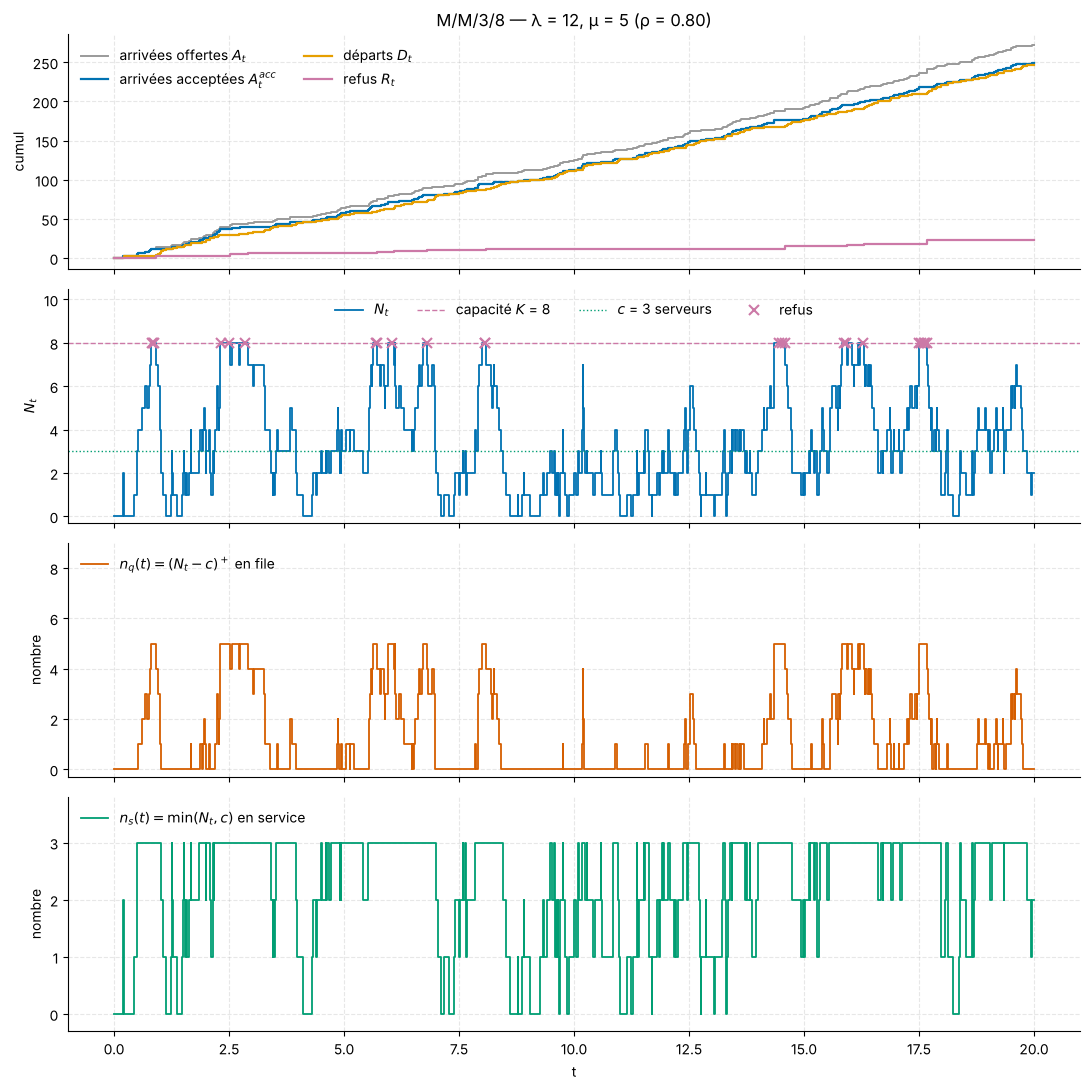

In [22]:
fig, axs = plt.subplots(4, 1, figsize=(11, 11), sharex=True)

ax = axs[0]
ax.step(tt, counting_process(tt, r2["T_all"]), where="post", color=C_GREY, lw=1.4, label=r"arrivées offertes $A_t$")
ax.step(tt, counting_process(tt, T), where="post", color=C_ARR, lw=1.6, label=r"arrivées acceptées $A^{acc}_t$")
ax.step(tt, counting_process(tt, np.sort(D)), where="post", color=C_DEP, lw=1.6, label=r"départs $D_t$")
ax.step(tt, counting_process(tt, T_ref), where="post", color=C_REF, lw=1.6, label=r"refus $R_t$")
ax.set(ylabel="cumul", title=fr"M/M/{c}/{K} — λ = {lam:g}, μ = {mu:g} (ρ = {th2['rho']:.2f})")
ax.legend(loc="upper left", ncol=2)

ax = axs[1]
ax.step(tt, NN, where="post", color=C_ARR, lw=1.3, label=r"$N_t$")
ax.axhline(K, color=C_REF, ls="--", lw=1, label=fr"capacité $K$ = {K}")
ax.axhline(c, color=C_SERV, ls=":", lw=1, label=fr"$c$ = {c} serveurs")
ax.plot(T_ref, np.full(T_ref.size, K), "x", color=C_REF, ms=7, mew=1.5, label="refus")
ax.set(ylabel=r"$N_t$", ylim=(-0.3, K + 2.5))
ax.legend(loc="upper center", ncol=4)

ax = axs[2]
ax.step(tt, np.maximum(NN - c, 0), where="post", color=C_QUEUE, lw=1.3, label=r"$n_q(t)=(N_t-c)^+$ en file")
ax.set(ylabel="nombre", ylim=(-0.3, K + 1))
ax.legend(loc="upper left")

ax = axs[3]
ax.step(tt, np.minimum(NN, c), where="post", color=C_SERV, lw=1.3, label=r"$n_s(t)=\min(N_t,c)$ en service")
ax.set(ylabel="nombre", xlabel="t", ylim=(-0.3, c + 0.8), yticks=range(c + 1))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Commentaires.**
- $N_t$ est borné par $K$ ; chaque arrivée qui survient quand $N_t=K$ est un refus (croix) et fait sauter $R_t$ au lieu de $N_t$.
- $n_s(t)$ sature à $c$ : tant que $N_t\le c$ il n'y a aucune attente ; la file $(N_t-c)^+$ ne se forme qu'au-delà de $c$ et ne dépasse jamais $K-c$.
- La courbe des arrivées acceptées s'infléchit pendant les périodes de saturation : ce n'est plus un processus de Poisson (ses accroissements dépendent de l'état).
- Les refus arrivent **en rafales** : ils se concentrent pendant les courtes périodes où $N_t=K$.

### Taux de perte le long d'une trajectoire

Sur une trajectoire longue, on suit trois estimateurs « en ligne » de la probabilité de refus, qui doivent tous converger vers $\pi_K$ :
1. la **proportion de clients refusés** $R_t/A_t$ ;
2. la **proportion du temps passé plein** $\frac1t\int_0^t\mathbf 1\{N_s=K\}\,ds$ ;
3. le **débit de perte** $R_t/t$, à comparer à $\lambda\pi_K$.

Sur [0, 2000] : 24249 arrivées, 1248 refus
  proportion de clients refusés R_t/A_t      = 0.0515
  proportion du temps où N_t = K            = 0.0539
  débit de perte R_t/t                      = 0.6240   (λ π_K = 0.6130)
  théorie : P_B = π_K                       = 0.0511


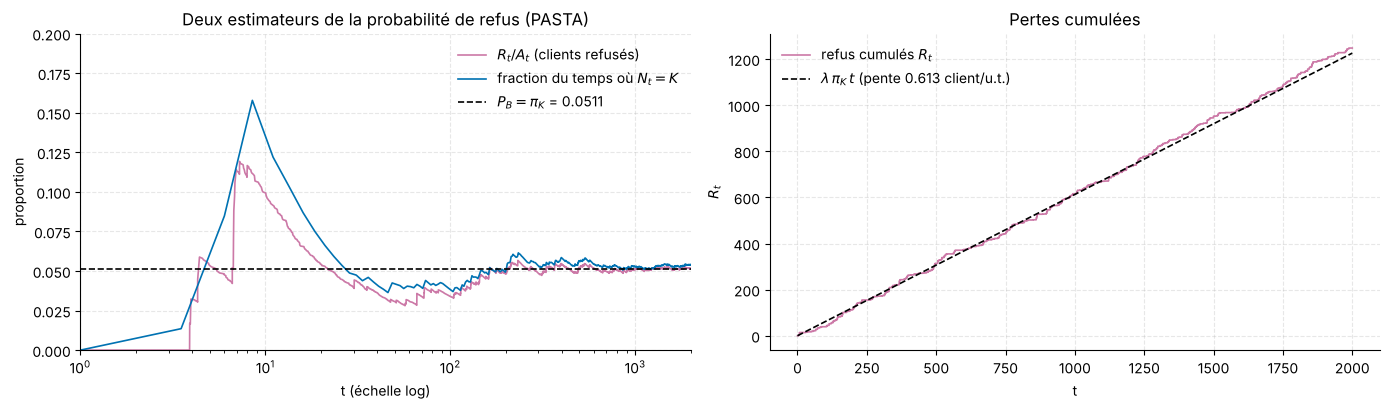

In [23]:
T_loss = 2000.0
r_loss = simulate_mmck(lam, mu, c, K, T_loss, np.random.default_rng(SEED + 3))
T_all, T_ref = r_loss["T_all"], r_loss["T_refused"]
R_at_arrivals = np.cumsum(~r_loss["accepted"])                       # R_t juste après chaque arrivée
loss_ratio = R_at_arrivals / np.arange(1, T_all.size + 1)            # R_t / A_t

# Proportion du temps plein sur [0, t] : intégrale exacte de 1{N_s = K}
tt, NN = step_path(r_loss["T"], r_loss["D"], T_loss)
time_full = np.concatenate(([0.0], np.cumsum(np.diff(tt) * (NN[:-1] == K))))
t_eval = np.linspace(1, T_loss, 800)
frac_full = np.interp(t_eval, tt, time_full) / t_eval

print(f"Sur [0, {T_loss:g}] : {T_all.size} arrivées, {T_ref.size} refus")
print(f"  proportion de clients refusés R_t/A_t      = {T_ref.size / T_all.size:.4f}")
print(f"  proportion du temps où N_t = K            = {time_full[-1] / T_loss:.4f}")
print(f"  débit de perte R_t/t                      = {T_ref.size / T_loss:.4f}   (λ π_K = {lam * th2['PB']:.4f})")
print(f"  théorie : P_B = π_K                       = {th2['PB']:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axs[0]
ax.plot(T_all, loss_ratio, color=C_REF, lw=1.2, label=r"$R_t/A_t$ (clients refusés)")
ax.plot(t_eval, frac_full, color=C_ARR, lw=1.2, label=r"fraction du temps où $N_t=K$")
ax.axhline(th2["PB"], color=C_THEO, ls="--", lw=1.2, label=fr"$P_B=\pi_K$ = {th2['PB']:.4f}")
ax.set(xscale="log", xlim=(1, T_loss), ylim=(0, 0.2), xlabel="t (échelle log)", ylabel="proportion",
       title="Deux estimateurs de la probabilité de refus (PASTA)")
ax.legend()
ax = axs[1]
ax.step(np.r_[0, T_ref, T_loss], np.r_[0, np.arange(1, T_ref.size + 1), T_ref.size], where="post",
        color=C_REF, lw=1.2, label=r"refus cumulés $R_t$")
ax.plot([0, T_loss], [0, lam * th2["PB"] * T_loss], color=C_THEO, ls="--", lw=1.2,
        label=fr"$\lambda\,\pi_K\,t$ (pente {lam * th2['PB']:.3f} client/u.t.)")
ax.set(xlabel="t", ylabel=r"$R_t$", title="Pertes cumulées")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Commentaires.**
- Les deux proportions convergent vers la même limite $\pi_K$ : c'est **PASTA**. Elles ne sont pas égales sur un horizon fini, mais leur écart tend vers 0.
- La convergence est lente et irrégulière : chaque épisode de saturation produit d'un coup plusieurs refus. Il faut donc beaucoup de données (ou plusieurs réplications, cf. II.4) pour estimer précisément une petite probabilité de refus.
- Les pertes cumulées croissent linéairement à la vitesse $\lambda\pi_K$ : c'est le **taux de perte** en clients par unité de temps.

## Question II.3 — Influence de $\lambda$, $\mu$, $c$ et $K$

*Correction.* À $c=3$, $K=8$, $\mu=5$, on fait varier $\lambda$ pour obtenir $\rho=0.4$, $0.8$, $1$ et $1.6$. Contrairement à M/M/1, **le cas $\rho\ge1$ reste stable** : c'est la probabilité de blocage qui absorbe l'excès de demande.

    ρ | P_B théo  P_B sim |  L théo   L sim |  W théo   W sim | λ_eff/λ
 0.40 |   0.0009   0.0009 |   1.289   1.307 |   0.215   0.220 |   0.999
 0.80 |   0.0511   0.0506 |   3.352   3.403 |   0.294   0.297 |   0.949
 1.00 |   0.1268   0.1304 |   4.521   4.578 |   0.345   0.350 |   0.873
 1.60 |   0.3850   0.3845 |   6.537   6.557 |   0.443   0.443 |   0.615


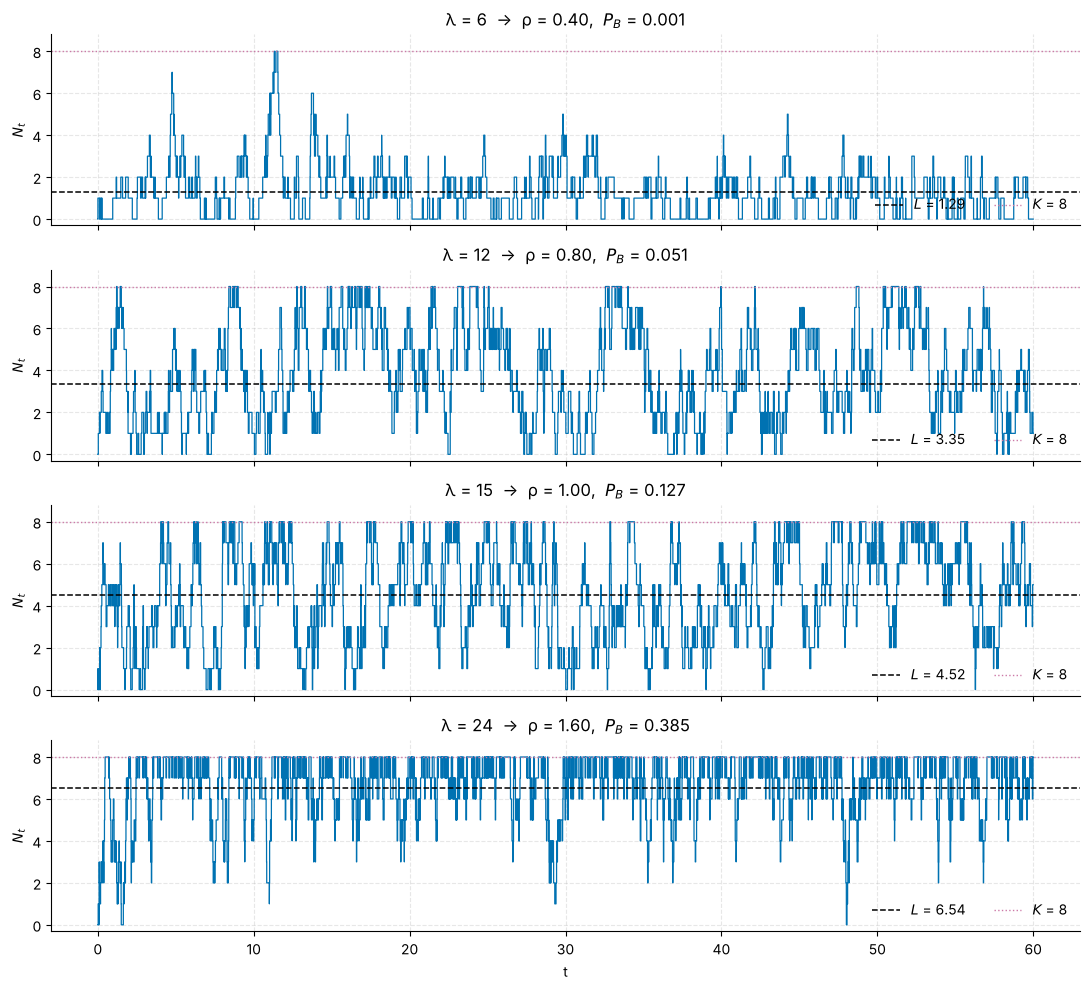

In [24]:
mu, c, K = 5.0, 3, 8
scen2 = [6.0, 12.0, 15.0, 24.0]                    # rho = 0.4, 0.8, 1.0, 1.6
T_plot, T_long, t_burn2 = 60.0, 5000.0, 50.0

fig, axs = plt.subplots(len(scen2), 1, figsize=(11, 10), sharex=True)
print(f"{'ρ':>5} | {'P_B théo':>8} {'P_B sim':>8} | {'L théo':>7} {'L sim':>7} | {'W théo':>7} {'W sim':>7} | {'λ_eff/λ':>7}")
for i, lam_i in enumerate(scen2):
    t_i = mmck_metrics(lam_i, mu, c, K)
    r_i = simulate_mmck(lam_i, mu, c, K, T_long, np.random.default_rng(SEED + 10 + i))
    win_all = r_i["T_all"] >= t_burn2
    PB_sim = np.mean(~r_i["accepted"][win_all])
    occ = occupation_measure(r_i["T"], r_i["D"], t_burn2, T_long)
    L_sim_i = occ @ np.arange(occ.size)
    W_sim_i = r_i["W"][r_i["T"] >= t_burn2].mean()
    print(f"{t_i['rho']:5.2f} | {t_i['PB']:8.4f} {PB_sim:8.4f} | {t_i['L']:7.3f} {L_sim_i:7.3f} | "
          f"{t_i['W']:7.3f} {W_sim_i:7.3f} | {1 - t_i['PB']:7.3f}")
    tt_i, NN_i = step_path(r_i["T"], r_i["D"], T_plot)
    ax = axs[i]
    ax.step(tt_i, NN_i, where="post", color=C_ARR, lw=0.9)
    ax.axhline(t_i["L"], color=C_THEO, ls="--", lw=1.1, label=fr"$L$ = {t_i['L']:.2f}")
    ax.axhline(K, color=C_REF, ls=":", lw=1, label=fr"$K$ = {K}")
    ax.set(ylabel=r"$N_t$", ylim=(-0.3, K + 0.8),
           title=fr"λ = {lam_i:g}  →  ρ = {t_i['rho']:.2f},  $P_B$ = {t_i['PB']:.3f}")
    ax.legend(loc="lower right", ncol=2)
axs[-1].set_xlabel("t")
plt.tight_layout()
plt.show()

  c   K      P_B       L       Wq       W   (ρ = 0.8, μ = 5)
  1   6   0.0663   2.142   0.3737   0.574
  2   7   0.0573   2.713   0.1598   0.360
  3   8   0.0511   3.352   0.0944   0.294
  5  10   0.0425   4.724   0.0467   0.247
 10  15   0.0300   8.392   0.0163   0.216


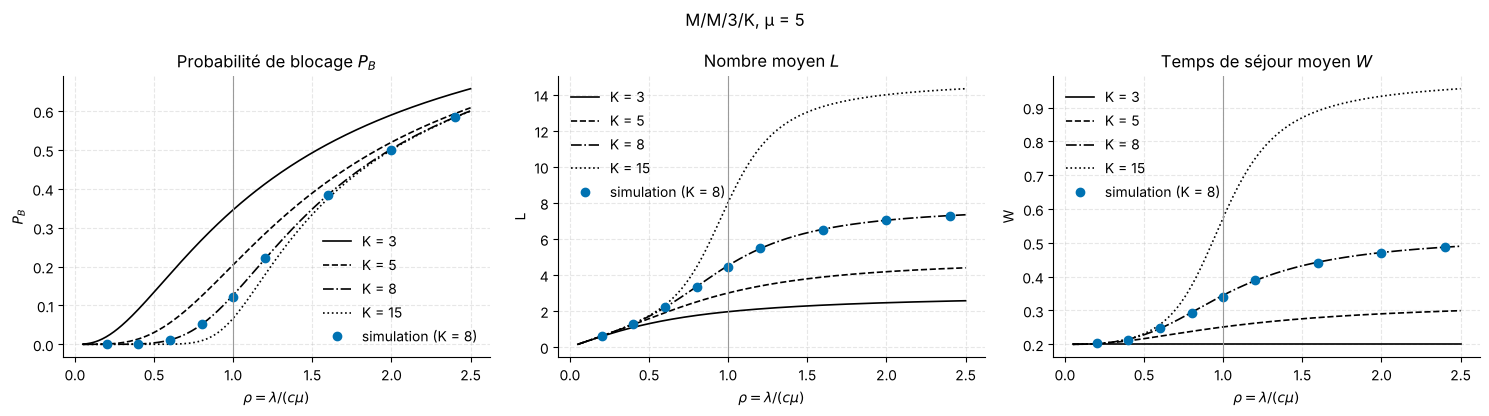

In [25]:
# Indicateurs théoriques en fonction de ρ pour plusieurs capacités K (c = 3), points simulés pour K = 8
rho_th = np.linspace(0.05, 2.5, 300)
K_list = [3, 5, 8, 15]
lam_sim = np.array([3, 6, 9, 12, 15, 18, 24, 30, 36])
sim_pts = []
for j, lam_j in enumerate(lam_sim):
    r_j = simulate_mmck(lam_j, mu, c, 8, 3000.0, np.random.default_rng(SEED + 200 + j))
    w = r_j["T_all"] >= 50
    occ = occupation_measure(r_j["T"], r_j["D"], 50.0, 3000.0)
    sim_pts.append((lam_j / (c * mu), np.mean(~r_j["accepted"][w]), occ @ np.arange(occ.size),
                    r_j["W"][r_j["T"] >= 50].mean()))
sim_pts = np.array(sim_pts)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
styles = ["-", "--", "-.", ":"]
for Kk, ls in zip(K_list, styles):
    M = [mmck_metrics(r_ * c * mu, mu, c, Kk) for r_ in rho_th]
    axs[0].plot(rho_th, [m_["PB"] for m_ in M], ls, color=C_THEO, lw=1.2, label=f"K = {Kk}")
    axs[1].plot(rho_th, [m_["L"] for m_ in M], ls, color=C_THEO, lw=1.2, label=f"K = {Kk}")
    axs[2].plot(rho_th, [m_["W"] for m_ in M], ls, color=C_THEO, lw=1.2, label=f"K = {Kk}")
for ax, col, ttl, yl in zip(axs, [1, 2, 3], ["Probabilité de blocage $P_B$", "Nombre moyen $L$", "Temps de séjour moyen $W$"],
                            ["$P_B$", "L", "W"]):
    ax.plot(sim_pts[:, 0], sim_pts[:, col], "o", color=C_ARR, label="simulation (K = 8)")
    ax.axvline(1, color=C_GREY, lw=0.8)
    ax.set(xlabel=r"$\rho=\lambda/(c\mu)$", ylabel=yl, title=ttl)
    ax.legend()
plt.suptitle(f"M/M/{c}/K, μ = {mu:g}", fontsize=12)
plt.tight_layout()
plt.show()

# Effet du nombre de serveurs à charge par serveur fixée (ρ = 0.8, K = c + 5 places d'attente)
print(f"{'c':>3} {'K':>3} {'P_B':>8} {'L':>7} {'Wq':>8} {'W':>7}   (ρ = 0.8, μ = 5)")
for cc in [1, 2, 3, 5, 10]:
    m_ = mmck_metrics(0.8 * cc * mu, mu, cc, cc + 5)
    print(f"{cc:3d} {cc + 5:3d} {m_['PB']:8.4f} {m_['L']:7.3f} {m_['Wq']:8.4f} {m_['W']:7.3f}")

**Commentaires.**
- **Toujours stable** : même à $\rho=1.6$, $N_t$ reste dans $\{0,\dots,K\}$ et $L$ est fini ; le prix à payer est un blocage massif (le système refuse environ la fraction $1-1/\rho$ de la demande quand $\rho$ est grand, puisque le débit de sortie sature à $c\mu$).
- Quand $\rho\gg1$, $N_t$ « colle » à $K$, $L\to K$ et $W\to K/(c\mu)$ : le temps de séjour est **borné** par la capacité, à l'opposé de M/M/1 où il explose.
- **Augmenter $K$** réduit le blocage mais allonge l'attente ; quand $K\to\infty$ avec $\rho<1$, on retrouve M/M/c. **$K=c$** supprime toute attente ($W=1/\mu$) au prix du blocage maximal (Erlang B).
- **Effet de mutualisation** : à charge par serveur $\rho$ fixée, plus de serveurs signifie moins d'attente et moins de blocage (dernier tableau) — un guichet unique servant $c$ files vaut mieux que $c$ guichets séparés.

### Dimensionnement : quelle capacité pour un taux de perte cible ?

La question pratique est souvent inverse : **quelle salle d'attente $K$ (ou combien de serveurs $c$) faut-il pour perdre au plus 5 %, 1 % ou 0,1 % des clients ?** Comme $\pi_K$ décroît avec $K$, il suffit d'augmenter $K$ jusqu'à passer sous la cible.

Pour $\rho<1$, $P_B$ décroît **géométriquement** en $K$ (comme $\rho^{K}$) : chaque place supplémentaire divise les pertes par environ $1/\rho$. Pour $\rho\ge1$, augmenter $K$ ne fait presque plus baisser les pertes : seule l'augmentation de la capacité de service $c\mu$ est efficace.

Capacité K minimale (c = 3, μ = 5) pour un taux de perte cible :
    ρ   P_B ≤ 5 %    ≤ 1 %   ≤ 0,1 %
 0.50           5        7        10
 0.80           9       15        25
 0.95          15       36        78
 1.20       > 500    > 500     > 500

Nombre minimal de serveurs (a = 8 Erlangs, 2 places d'attente) :
  P_B ≤   5 % : c = 11
  P_B ≤   1 % : c = 14
  P_B ≤ 0,1 % : c = 17


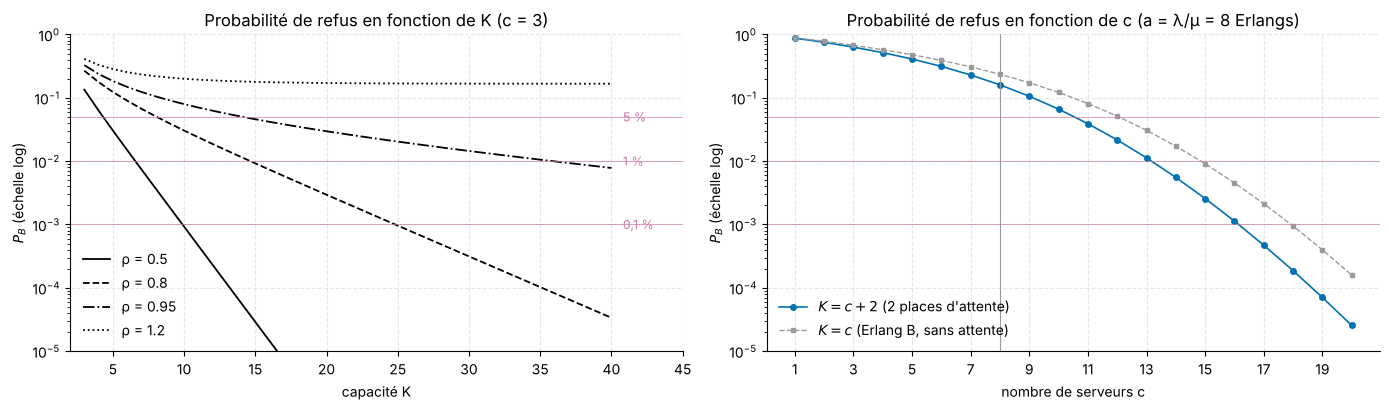

In [26]:
def K_min(lam, mu, c, target, K_max=500):
    """Plus petite capacité K >= c telle que P_B <= target (None si non atteinte)."""
    for Kk in range(c, K_max + 1):
        if mmck_stationary(lam, mu, c, Kk)[-1] <= target:
            return Kk
    return None


def c_min(lam, mu, waiting_places, target, c_max=200):
    """Plus petit nombre de serveurs c tel que P_B <= target, avec K = c + places d'attente."""
    for cc in range(1, c_max + 1):
        if mmck_stationary(lam, mu, cc, cc + waiting_places)[-1] <= target:
            return cc


mu, c = 5.0, 3
targets = [0.05, 0.01, 0.001]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
K_range = np.arange(c, 41)
for rho_i, ls in zip([0.5, 0.8, 0.95, 1.2], ["-", "--", "-.", ":"]):
    PB_K = [mmck_stationary(rho_i * c * mu, mu, c, Kk)[-1] for Kk in K_range]
    axs[0].semilogy(K_range, PB_K, ls, color=C_THEO, lw=1.3, label=fr"ρ = {rho_i}")
for target, lab in zip(targets, ["5 %", "1 %", "0,1 %"]):
    axs[0].axhline(target, color=C_REF, lw=0.7, alpha=0.7)
    axs[0].text(40.8, target, lab, va="center", color=C_REF, fontsize=9)
axs[0].set(xlabel="capacité K", ylabel=r"$P_B$ (échelle log)", ylim=(1e-5, 1), xlim=(2, 45),
           title=fr"Probabilité de refus en fonction de K (c = {c})")
axs[0].legend(loc="lower left")

# Effet du nombre de serveurs à charge offerte fixée a = λ/μ = 8 Erlangs
a_fix = 8.0
c_range = np.arange(1, 21)
axs[1].semilogy(c_range, [mmck_stationary(a_fix * mu, mu, cc, cc + 2)[-1] for cc in c_range], "o-",
                color=C_ARR, ms=4, lw=1.2, label=r"$K=c+2$ (2 places d'attente)")
axs[1].semilogy(c_range, [erlang_b(cc, a_fix) for cc in c_range], "s--", color=C_GREY, ms=3, lw=1,
                label=r"$K=c$ (Erlang B, sans attente)")
axs[1].axvline(a_fix, color=C_GREY, lw=0.8)
for target in targets:
    axs[1].axhline(target, color=C_REF, lw=0.7, alpha=0.7)
axs[1].set(xlabel="nombre de serveurs c", ylabel=r"$P_B$ (échelle log)", ylim=(1e-5, 1), xticks=c_range[::2],
           title=fr"Probabilité de refus en fonction de c (a = λ/μ = {a_fix:g} Erlangs)")
axs[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

print(f"Capacité K minimale (c = {c}, μ = {mu:g}) pour un taux de perte cible :")
print(f"{'ρ':>5} {'P_B ≤ 5 %':>11} {'≤ 1 %':>8} {'≤ 0,1 %':>9}")
for rho_i in [0.5, 0.8, 0.95, 1.2]:
    ks = [K_min(rho_i * c * mu, mu, c, tg) for tg in targets]
    print(f"{rho_i:5.2f} " + " ".join(f"{(str(k) if k else '> 500'):>{w}}" for k, w in zip(ks, (11, 8, 9))))
print(f"\nNombre minimal de serveurs (a = {a_fix:g} Erlangs, 2 places d'attente) :")
for tg, lab in zip(targets, ["5 %", "1 %", "0,1 %"]):
    print(f"  P_B ≤ {lab:>5} : c = {c_min(a_fix * mu, mu, 2, tg)}")

**Commentaires.**
- Pour $\rho<1$, les courbes sont des droites en échelle log : quelques places supplémentaires suffisent à diviser les pertes par 10, d'autant moins qu'on est loin de la saturation.
- Près de la saturation ($\rho=0.95$) il faut des capacités beaucoup plus grandes ; au-delà ($\rho=1.2$), $P_B$ plafonne vers $1-1/\rho\approx17\,\%$ quel que soit $K$ : **une salle d'attente ne remplace pas un serveur**.
- À droite, le seuil $c\approx a$ (trait vertical) sépare deux régimes : avec moins de $a$ serveurs, les pertes restent massives ; au-delà, chaque serveur ajouté les fait chuter très vite. Quelques places d'attente ($K=c+2$) réduisent sensiblement les pertes par rapport au modèle d'Erlang B sans attente.

## Question II.4 — Étude Monte Carlo ($B=1000$ réplications)

*Correction.* Même méthodologie qu'en I.4 (IC de Student/normal justifié par le TCL sur des réplications i.i.d. ; $N_t\le K$ est même borné). Paramètres : $\lambda=12$, $\mu=5$, $c=3$, $K=8$. On estime en plus $P_B$ et $\lambda_{\rm eff}$ (étude détaillée de la probabilité de refus à la fin de la question) et on vérifie PASTA : la loi de l'état **vu par les arrivants** doit être $\pi$, et en particulier $\mathbb P(\text{arrivant voit }K)=\pi_K=P_B$.

On prend une période de chauffe $t_0=30$ : les histogrammes de la loi transitoire (plus bas) montrent que la loi de $N_t$ est déjà stationnaire vers $t\approx2$.

In [27]:
lam, mu, c, K = 12.0, 5.0, 3, 8
th2 = mmck_metrics(lam, mu, c, K)
birth2, death2 = mmck_rates(lam, mu, c, K)

B = 1000
T_max2, t_burn2 = 150.0, 30.0                     # horizon et période de chauffe
t_grid2 = np.linspace(0, 8, 321)
rng = np.random.default_rng(SEED)

N_grid2 = np.empty((B, t_grid2.size), dtype=int)
stats2 = {k: np.empty(B) for k in ["L", "Lq", "W", "Wq", "PB", "PB_time", "loss_rate", "n_offered",
                                    "lam_eff", "busy", "varN"]}
R_grid2 = np.empty((B, t_grid2.size), dtype=int)  # refus cumulés R_t sur la grille
seen_counts = np.zeros(K + 1)
Wq_acc_pool = []
for b in range(B):
    r_b = simulate_mmck(lam, mu, c, K, T_max2, rng)
    N_grid2[b] = N_process(t_grid2, r_b["T"], r_b["D"])
    R_grid2[b] = counting_process(t_grid2, r_b["T_refused"])
    occ = np.pad(occupation_measure(r_b["T"], r_b["D"], t_burn2, T_max2), (0, K + 1))[:K + 1]
    n = np.arange(K + 1)
    stats2["L"][b] = occ @ n
    stats2["Lq"][b] = occ @ np.maximum(n - c, 0)
    stats2["busy"][b] = occ @ np.minimum(n, c)
    stats2["varN"][b] = occ @ n**2 - stats2["L"][b]**2
    w_all = r_b["T_all"] >= t_burn2
    w_acc = r_b["T"] >= t_burn2
    stats2["PB"][b] = np.mean(~r_b["accepted"][w_all])                          # proportion de clients refusés
    stats2["PB_time"][b] = occ[K]                                                # proportion du temps plein
    stats2["loss_rate"][b] = np.sum(~r_b["accepted"][w_all]) / (T_max2 - t_burn2)  # refus par unité de temps
    stats2["n_offered"][b] = w_all.sum()
    stats2["lam_eff"][b] = w_acc.sum() / (T_max2 - t_burn2)
    stats2["W"][b], stats2["Wq"][b] = r_b["W"][w_acc].mean(), r_b["Wq"][w_acc].mean()
    seen_counts += np.bincount(r_b["n_seen"][w_all], minlength=K + 1)
    Wq_acc_pool.append(r_b["Wq"][w_acc])
Wq_acc_pool = np.concatenate(Wq_acc_pool)
print(f"{B} réplications simulées ; {int(seen_counts.sum()):,} arrivées offertes en régime stationnaire.")

1000 réplications simulées ; 1,439,348 arrivées offertes en régime stationnaire.


Part des instants où E[N_t] théorique est dans l'IC 95 % : 94.4%


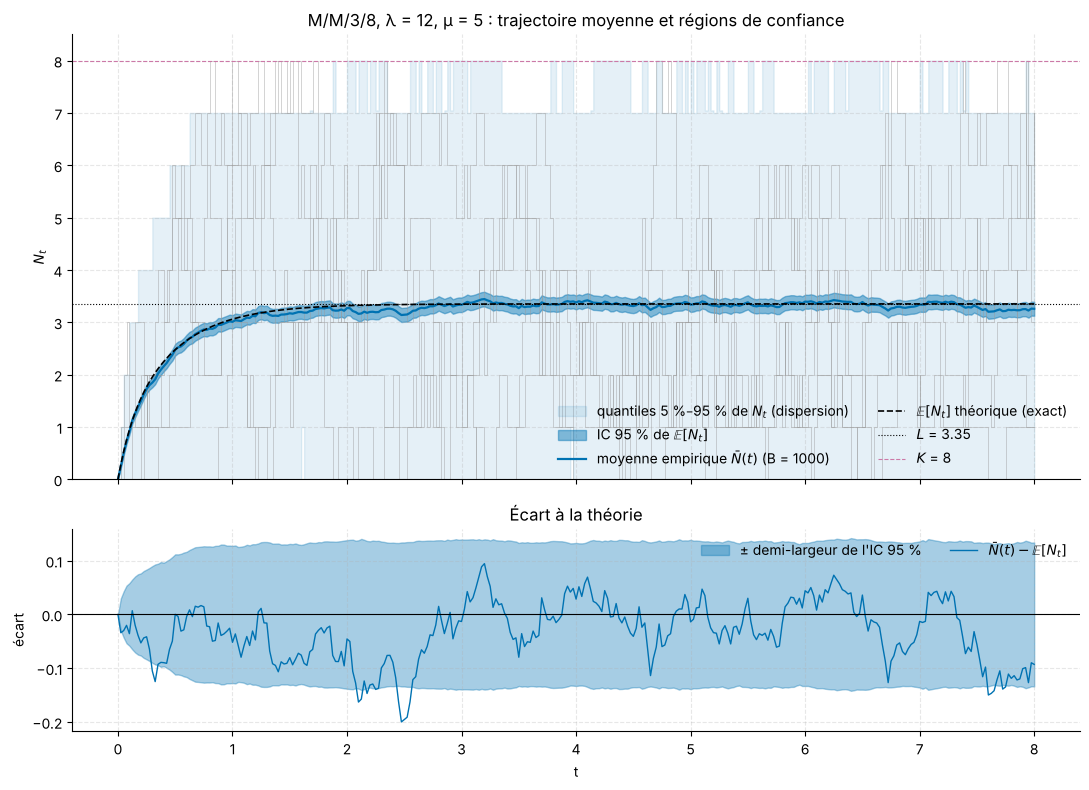

In [28]:
p0 = np.zeros(K + 1); p0[0] = 1.0
P_theo2 = bd_transient(birth2, death2, p0, t_grid2)      # exact : espace d'états fini
m_theo2 = P_theo2 @ np.arange(K + 1)
pi2 = mmck_stationary(lam, mu, c, K)

m_hat2 = N_grid2.mean(axis=0)
s_hat2 = N_grid2.std(axis=0, ddof=1)
h2 = stats.t.ppf(0.975, B - 1) * s_hat2 / np.sqrt(B)
q05, q95 = np.quantile(N_grid2, [0.05, 0.95], axis=0)
print(f"Part des instants où E[N_t] théorique est dans l'IC 95 % : {np.mean(np.abs(m_hat2 - m_theo2) <= h2):.1%}")

fig, axs = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axs[0]
for b in range(5):
    ax.step(t_grid2, N_grid2[b], where="post", color=C_GREY, lw=0.5, alpha=0.6)
ax.fill_between(t_grid2, q05, q95, step="post", color=C_ARR, alpha=0.10, label="quantiles 5 %–95 % de $N_t$ (dispersion)")
ax.fill_between(t_grid2, m_hat2 - h2, m_hat2 + h2, color=C_ARR, alpha=0.45, label=r"IC 95 % de $\mathbb{E}[N_t]$")
ax.plot(t_grid2, m_hat2, color=C_ARR, lw=1.6, label=fr"moyenne empirique $\bar N(t)$ (B = {B})")
ax.plot(t_grid2, m_theo2, color=C_THEO, lw=1.2, ls="--", label=r"$\mathbb{E}[N_t]$ théorique (exact)")
ax.axhline(th2["L"], color=C_THEO, lw=0.8, ls=":", label=fr"$L$ = {th2['L']:.2f}")
ax.axhline(K, color=C_REF, lw=0.8, ls="--", label=fr"$K$ = {K}")
ax.set(ylabel=r"$N_t$", ylim=(0, K + 0.5),
       title=fr"M/M/{c}/{K}, λ = {lam:g}, μ = {mu:g} : trajectoire moyenne et régions de confiance")
ax.legend(loc="lower right", ncol=2)

ax = axs[1]
ax.fill_between(t_grid2, -h2, h2, color=C_ARR, alpha=0.35, label="± demi-largeur de l'IC 95 %")
ax.plot(t_grid2, m_hat2 - m_theo2, color=C_ARR, lw=1.0, label=r"$\bar N(t)-\mathbb{E}[N_t]$")
ax.axhline(0, color=C_THEO, lw=0.8)
ax.set(xlabel="t", ylabel="écart", title="Écart à la théorie")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

In [29]:
print("Estimateurs stationnaires (une valeur par réplication) :\n")
print_table([("L", stats2["L"], th2["L"]), ("Lq", stats2["Lq"], th2["Lq"]),
             ("W", stats2["W"], th2["W"]), ("Wq", stats2["Wq"], th2["Wq"]),
             ("P_B", stats2["PB"], th2["PB"]), ("λ_eff", stats2["lam_eff"], th2["lam_eff"]),
             ("serv.occ.", stats2["busy"], th2["busy"])])

n = np.arange(K + 1)
print(f"\nÉcart-type intrinsèque de N : {np.sqrt(stats2['varN'].mean()):.3f}   (théorie {np.sqrt(n**2 @ pi2 - th2['L']**2):.3f})")

print("\nLoi de Little — avec quel débit ?")
print(f"  moyenne de L̂              = {stats2['L'].mean():.4f}   (théorie {th2['L']:.4f})")
print(f"  moyenne de λ̂_eff · Ŵ      = {(stats2['lam_eff'] * stats2['W']).mean():.4f}   ← correct")
print(f"  λ · moyenne de Ŵ  (faux)  = {lam * stats2['W'].mean():.4f}   ← surestime L de {lam / th2['lam_eff'] - 1:.1%}")
print(f"\nP(Wq = 0 | accepté) : {np.mean(Wq_acc_pool == 0):.4f}   (théorie Σ_(n<c) π_n / (1-π_K) = {th2['P_no_wait']:.4f})")

Estimateurs stationnaires (une valeur par réplication) :

Grandeur    moyenne MC  écart-type               IC 95 %   théorie  dans IC
---------------------------------------------------------------------------
L               3.3475      0.1895   [  3.3358,   3.3593]    3.3519      oui
Lq              1.0716      0.1310   [  1.0634,   1.0797]    1.0745      oui
W               0.2940      0.0154   [  0.2930,   0.2949]    0.2944      oui
Wq              0.0941      0.0111   [  0.0934,   0.0948]    0.0944      oui
P_B             0.0504      0.0123   [  0.0496,   0.0512]    0.0511      oui
λ_eff          11.3879      0.2565   [ 11.3720,  11.4038]   11.3870      oui
serv.occ.       2.2760      0.0669   [  2.2718,   2.2801]    2.2774      oui

Écart-type intrinsèque de N : 2.197   (théorie 2.207)

Loi de Little — avec quel débit ?
  moyenne de L̂              = 3.3475   (théorie 3.3519)
  moyenne de λ̂_eff · Ŵ      = 3.3477   ← correct
  λ · moyenne de Ŵ  (faux)  = 3.5277   ← surestime L d

**Commentaires.**
- La trajectoire moyenne atteint son palier bien plus vite qu'en I.4 : l'espace d'états est petit et le débit de service total atteint $c\mu=15$.
- Tous les estimateurs, y compris $P_B$ et $\lambda_{\rm eff}$, sont compatibles avec la théorie ; le nombre moyen de serveurs occupés vaut $\lambda_{\rm eff}/\mu$ (et non $\lambda/\mu$).
- **Little doit être appliquée avec le débit effectif** : utiliser $\lambda$ revient à compter des clients refusés qui ne séjournent jamais dans le système, et surestime $L$ du facteur $1/(1-P_B)$.

### Probabilité de refus et taux de perte : étude Monte Carlo

On exploite les $B$ réplications sous trois angles.

1. **Régime transitoire.** Un client qui arrive à l'instant $t$ est refusé avec probabilité $p_K(t)=\mathbb P(N_t=K)$, estimée par la moyenne des indicatrices $\mathbf 1\{N^{(b)}_t=K\}$ (IC de Student, comme pour $\bar N(t)$). Le nombre moyen de refus sur $[0,t]$ vaut $\mathbb E[R_t]=\lambda\int_0^t p_K(s)\,ds$.
2. **Régime stationnaire, trois estimateurs de $P_B$** sur chaque réplication (fenêtre $[t_0,T_{\max}]$) : la proportion de clients refusés, la proportion du temps passé plein, et le débit de perte divisé par $\lambda$. Par PASTA, les trois ont la même limite $\pi_K$.
3. **Loi de l'estimateur $\hat P_B$.** D'une réplication à l'autre, $\hat P_B^{(b)}$ fluctue ; par le TCL sa loi est approximativement normale. On compare aussi son écart-type à celui qu'on obtiendrait si les refus étaient des tirages **indépendants** (loi binomiale), $\sqrt{P_B(1-P_B)/n}$ avec $n$ le nombre d'arrivées.

Refus moyens sur [0, 8] : 4.155  IC 95 % [3.872, 4.438]   théorie 4.387   (λ π_K t = 4.904)


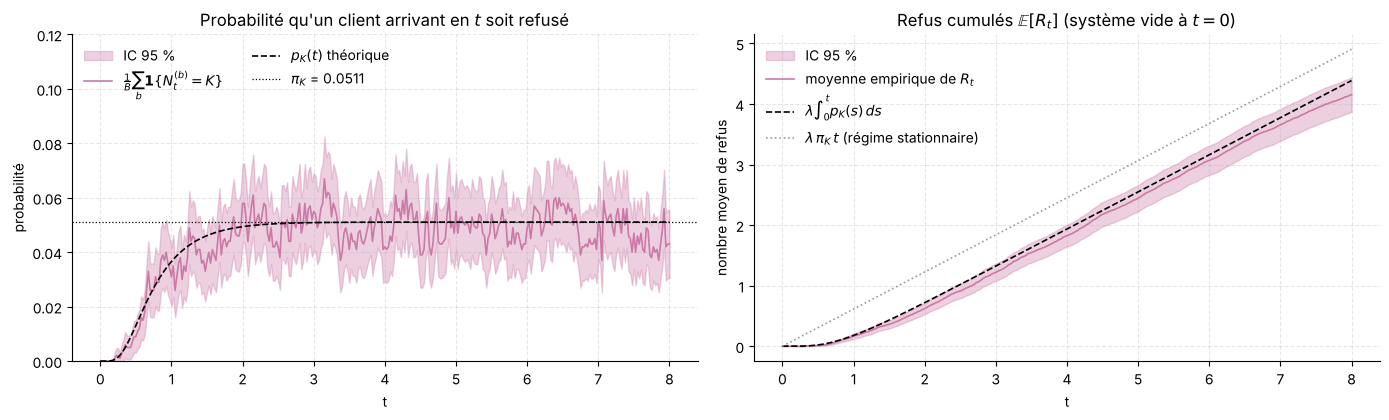

In [30]:
# (1) Régime transitoire : probabilité de refus p_K(t) et refus cumulés E[R_t]
full = (N_grid2 == K).astype(float)
pK_hat = full.mean(axis=0)
pK_h = stats.t.ppf(0.975, B - 1) * full.std(axis=0, ddof=1) / np.sqrt(B)
pK_theo = P_theo2[:, K]

R_hat = R_grid2.mean(axis=0)
R_h = stats.t.ppf(0.975, B - 1) * R_grid2.std(axis=0, ddof=1) / np.sqrt(B)
dt = np.diff(t_grid2)
R_theo = lam * np.concatenate(([0.0], np.cumsum(0.5 * (pK_theo[1:] + pK_theo[:-1]) * dt)))  # λ ∫ p_K

fig, axs = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axs[0]
ax.fill_between(t_grid2, pK_hat - pK_h, pK_hat + pK_h, color=C_REF, alpha=0.35, label="IC 95 %")
ax.plot(t_grid2, pK_hat, color=C_REF, lw=1.2, label=r"$\frac{1}{B}\sum_b \mathbf{1}\{N^{(b)}_t=K\}$")
ax.plot(t_grid2, pK_theo, color=C_THEO, ls="--", lw=1.2, label=r"$p_K(t)$ théorique")
ax.axhline(th2["PB"], color=C_THEO, ls=":", lw=0.9, label=fr"$\pi_K$ = {th2['PB']:.4f}")
ax.set(xlabel="t", ylabel="probabilité", ylim=(0, 0.12), title="Probabilité qu'un client arrivant en $t$ soit refusé")
ax.legend(loc="upper left", ncol=2)
ax = axs[1]
ax.fill_between(t_grid2, R_hat - R_h, R_hat + R_h, color=C_REF, alpha=0.35, label="IC 95 %")
ax.plot(t_grid2, R_hat, color=C_REF, lw=1.2, label=r"moyenne empirique de $R_t$")
ax.plot(t_grid2, R_theo, color=C_THEO, ls="--", lw=1.2, label=r"$\lambda\int_0^t p_K(s)\,ds$")
ax.plot(t_grid2, lam * th2["PB"] * t_grid2, color=C_GREY, ls=":", lw=1.2, label=r"$\lambda\,\pi_K\,t$ (régime stationnaire)")
ax.set(xlabel="t", ylabel="nombre moyen de refus", title=r"Refus cumulés $\mathbb{E}[R_t]$ (système vide à $t=0$)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"Refus moyens sur [0, {t_grid2[-1]:g}] : {R_hat[-1]:.3f}  IC 95 % [{R_hat[-1] - R_h[-1]:.3f}, {R_hat[-1] + R_h[-1]:.3f}]"
      f"   théorie {R_theo[-1]:.3f}   (λ π_K t = {lam * th2['PB'] * t_grid2[-1]:.3f})")

Trois estimateurs de la probabilité de refus (une valeur par réplication) :

Grandeur    moyenne MC  écart-type               IC 95 %   théorie  dans IC
---------------------------------------------------------------------------
refusés         0.0504      0.0123   [  0.0496,   0.0512]    0.0511      oui
temps K         0.0506      0.0116   [  0.0499,   0.0513]    0.0511      oui
perte/λ         0.0506      0.0130   [  0.0497,   0.0514]    0.0511      oui

Taux de perte (clients perdus par unité de temps) : 0.6067  IC 95 % [0.5970, 0.6163]   théorie λ π_K = 0.6130
Débit servi λ_eff = 11.3879  +  débit perdu = 0.6067  =  11.9946   (λ = 12)

Écart-type de P̂_B entre réplications : 0.0123
Écart-type si les refus étaient indépendants (binomial, n ≈ 1439 arrivées) : 0.0058
Rapport ≈ 2.11 : refus groupés en rafales -> variance 4.5 fois plus grande


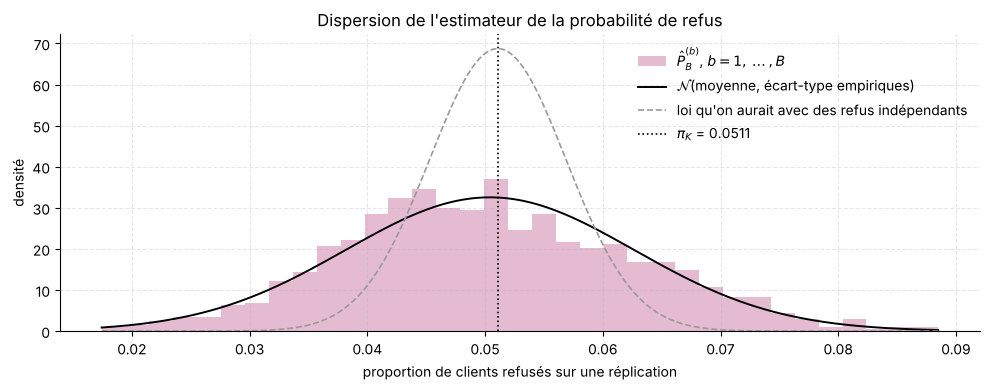

In [31]:
# (2) Trois estimateurs stationnaires de P_B
print("Trois estimateurs de la probabilité de refus (une valeur par réplication) :\n")
print_table([("refusés", stats2["PB"], th2["PB"]),
             ("temps K", stats2["PB_time"], th2["PB"]),
             ("perte/λ", stats2["loss_rate"] / lam, th2["PB"])])
m_loss, s_loss, lo_loss, hi_loss = mc_summary(stats2["loss_rate"])
print(f"\nTaux de perte (clients perdus par unité de temps) : {m_loss:.4f}  IC 95 % [{lo_loss:.4f}, {hi_loss:.4f}]"
      f"   théorie λ π_K = {lam * th2['PB']:.4f}")
print(f"Débit servi λ_eff = {stats2['lam_eff'].mean():.4f}  +  débit perdu = {m_loss:.4f}"
      f"  =  {stats2['lam_eff'].mean() + m_loss:.4f}   (λ = {lam:g})")

# (3) Loi de l'estimateur et comparaison avec l'hypothèse de refus indépendants
n_mean = stats2["n_offered"].mean()
sd_binom = np.sqrt(th2["PB"] * (1 - th2["PB"]) / n_mean)
sd_obs = stats2["PB"].std(ddof=1)
print(f"\nÉcart-type de P̂_B entre réplications : {sd_obs:.4f}")
print(f"Écart-type si les refus étaient indépendants (binomial, n ≈ {n_mean:.0f} arrivées) : {sd_binom:.4f}")
print(f"Rapport ≈ {sd_obs / sd_binom:.2f} : refus groupés en rafales -> variance {(sd_obs / sd_binom)**2:.1f} fois plus grande")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(stats2["PB"], bins=35, density=True, color=C_REF, alpha=0.5, label=r"$\hat P_B^{(b)}$, $b=1,\dots,B$")
x = np.linspace(stats2["PB"].min(), stats2["PB"].max(), 300)
ax.plot(x, stats.norm.pdf(x, stats2["PB"].mean(), sd_obs), color=C_THEO, lw=1.4,
        label=fr"$\mathcal{{N}}$(moyenne, écart-type empiriques)")
ax.plot(x, stats.norm.pdf(x, th2["PB"], sd_binom), color=C_GREY, ls="--", lw=1.2,
        label="loi qu'on aurait avec des refus indépendants")
ax.axvline(th2["PB"], color=C_THEO, ls=":", lw=1.2, label=fr"$\pi_K$ = {th2['PB']:.4f}")
ax.set(xlabel="proportion de clients refusés sur une réplication", ylabel="densité",
       title="Dispersion de l'estimateur de la probabilité de refus")
ax.legend()
plt.tight_layout()
plt.show()

**Commentaires.**
- **Transitoire.** Partant du système vide, aucun client n'est refusé au début : $p_K(t)$ part de 0 et rejoint $\pi_K$ en deux unités de temps environ. Les refus cumulés sont donc d'abord **inférieurs** à la droite $\lambda\pi_K t$, puis lui deviennent parallèles. Dans les deux cas, la théorie (exacte) reste dans les bandes de confiance.
- **Stationnaire.** Proportion de clients refusés, proportion du temps plein et débit de perte divisé par $\lambda$ estiment tous $\pi_K$ (PASTA). Le bilan de flux $\lambda=\lambda_{\rm eff}+\lambda\pi_K$ est vérifié : chaque client offert est soit servi, soit perdu.
- **Précision.** La loi de $\hat P_B$ est bien approximativement normale (TCL), mais son écart-type est nettement plus grand que celui d'un modèle binomial : les refus ne sont **pas indépendants**, ils arrivent en rafales pendant les épisodes de saturation. Un IC « binomial » $\hat P_B\pm1.96\sqrt{\hat P_B(1-\hat P_B)/n}$ calculé sur une seule trajectoire serait donc **beaucoup trop optimiste** ; les réplications indépendantes donnent, elles, un IC honnête.

### Loi des états : régimes transitoire et stationnaire

    t  TV(emp, p(t))  TV(p(t), π)  χ² p-valeur
  0.1         0.0219       0.5262        0.400
 0.25         0.0181       0.3216        0.808
  0.5         0.0300       0.1721        0.363
    1         0.0452       0.0566        0.139
    2         0.0276       0.0065        0.644
    8         0.0414       0.0000        0.396


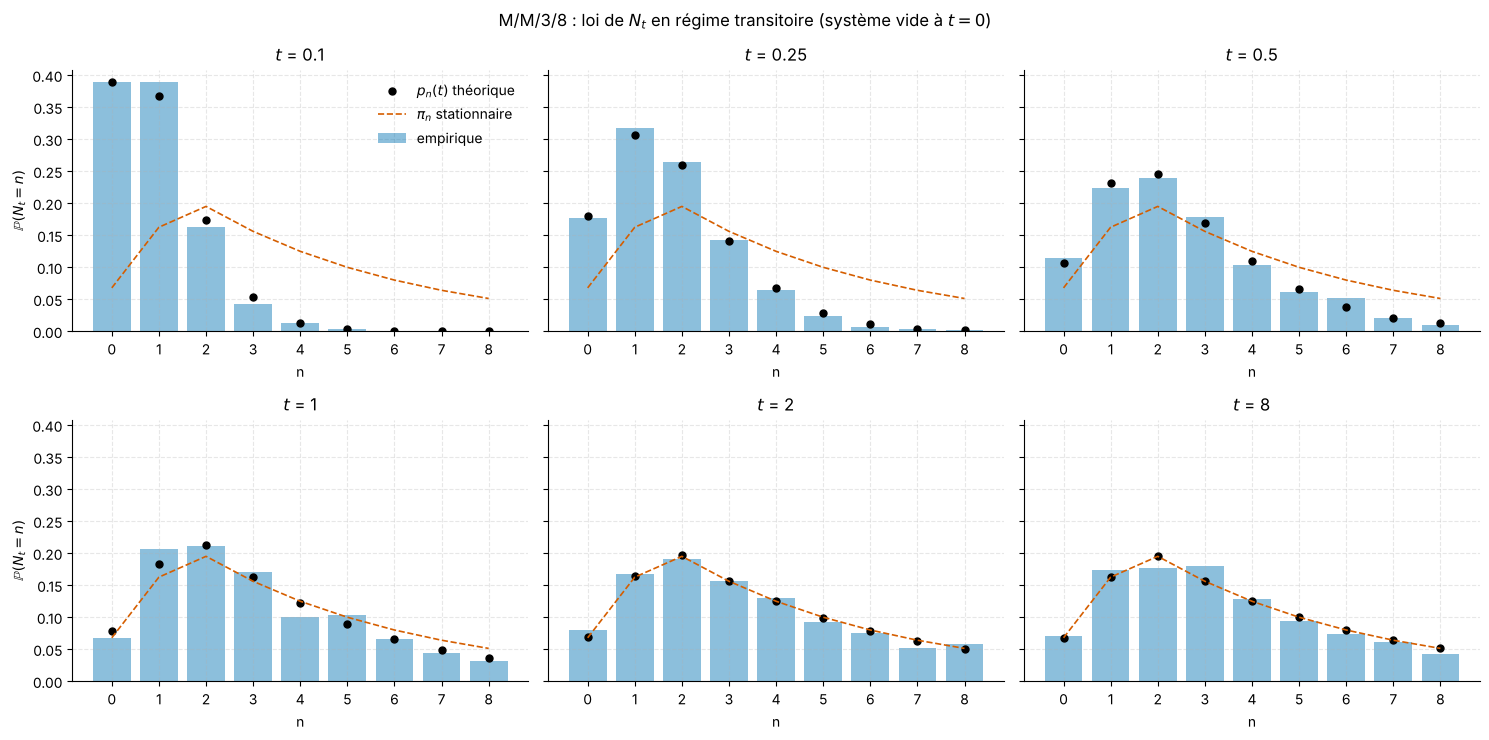

In [32]:
t_show2 = [0.1, 0.25, 0.5, 1.0, 2.0, 8.0]
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
print(f"{'t':>5} {'TV(emp, p(t))':>14} {'TV(p(t), π)':>12} {'χ² p-valeur':>12}")
for ax, t_s in zip(axs.ravel(), t_show2):
    i = np.argmin(np.abs(t_grid2 - t_s))
    sample = N_grid2[:, i]
    emp = np.bincount(sample, minlength=K + 1) / B
    ax.bar(n, emp, width=0.8, color=C_ARR, alpha=0.45, label="empirique")
    ax.plot(n, P_theo2[i], "o", color=C_THEO, ms=5, label=r"$p_n(t)$ théorique")
    ax.plot(n, pi2, "--", color=C_QUEUE, lw=1.2, label=r"$\pi_n$ stationnaire")
    _, pval, _ = chi2_gof(sample, P_theo2[i])
    print(f"{t_s:5g} {total_variation(emp, P_theo2[i]):14.4f} {total_variation(P_theo2[i], pi2):12.4f} {pval:12.3f}")
    ax.set(title=fr"$t$ = {t_grid2[i]:g}", xlabel="n", xticks=n)
for ax in axs[:, 0]:
    ax.set_ylabel(r"$\mathbb{P}(N_t=n)$")
axs[0, 0].legend()
plt.suptitle(fr"M/M/{c}/{K} : loi de $N_t$ en régime transitoire (système vide à $t=0$)", fontsize=12)
plt.tight_layout()
plt.show()

(1) N_t en t = 8 sur B réplications : χ² p-valeur = 0.396
(2) Occupation d'une trajectoire de durée 20 000 : TV(occupation, π) = 0.0038
(3) PASTA, état vu par les arrivants : TV(vu, π) = 0.0008 ;  P(arrivant voit K) = 0.0506  vs  π_K = P_B = 0.0511


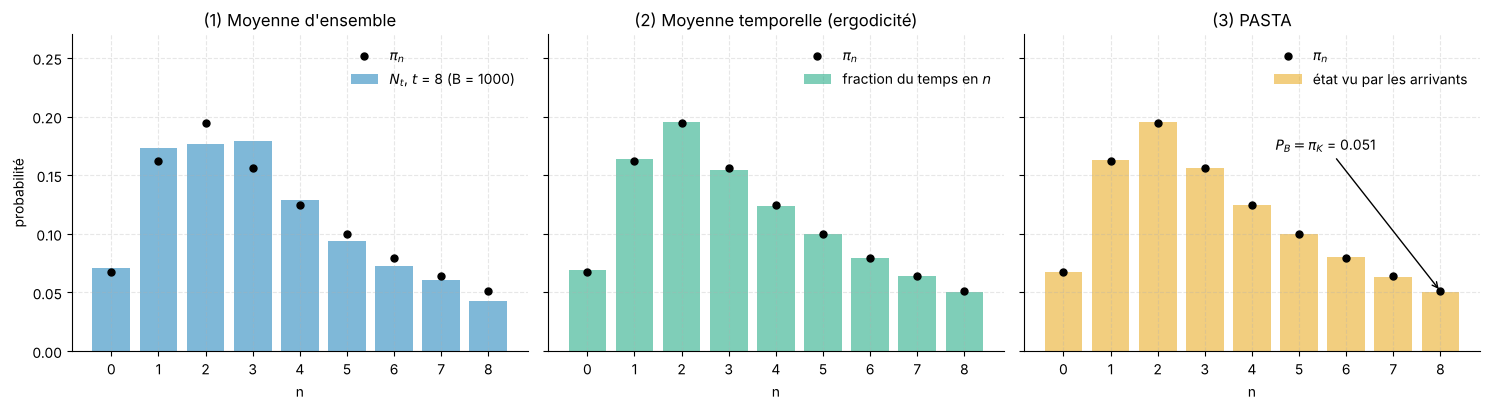

In [33]:
r_long2 = simulate_mmck(lam, mu, c, K, 20_000.0, np.random.default_rng(SEED + 7))
occ_long2 = np.pad(occupation_measure(r_long2["T"], r_long2["D"], 0.0, 20_000.0), (0, K + 1))[:K + 1]
emp_end2 = np.bincount(N_grid2[:, -1], minlength=K + 1) / B
seen_freq = seen_counts / seen_counts.sum()

_, p_sp, _ = chi2_gof(N_grid2[:, -1], pi2)
print(f"(1) N_t en t = {t_grid2[-1]:g} sur B réplications : χ² p-valeur = {p_sp:.3f}")
print(f"(2) Occupation d'une trajectoire de durée 20 000 : TV(occupation, π) = {total_variation(occ_long2, pi2):.4f}")
print(f"(3) PASTA, état vu par les arrivants : TV(vu, π) = {total_variation(seen_freq, pi2):.4f} ;  "
      f"P(arrivant voit K) = {seen_freq[K]:.4f}  vs  π_K = P_B = {pi2[K]:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
panels = [(emp_end2, C_ARR, fr"$N_t$, $t$ = {t_grid2[-1]:g} (B = {B})", "(1) Moyenne d'ensemble"),
          (occ_long2, C_SERV, "fraction du temps en $n$", "(2) Moyenne temporelle (ergodicité)"),
          (seen_freq, C_DEP, "état vu par les arrivants", "(3) PASTA")]
for ax, (vals, col, lab, ttl) in zip(axs, panels):
    ax.bar(n, vals, width=0.8, color=col, alpha=0.5, label=lab)
    ax.plot(n, pi2, "o", color=C_THEO, ms=5, label=r"$\pi_n$")
    ax.set(title=ttl, xlabel="n", xticks=n, ylim=(0, 0.27))
    ax.legend(loc="upper right")
axs[2].annotate(fr"$P_B=\pi_K$ = {pi2[K]:.3f}", xy=(K, pi2[K]), xytext=(K - 3.5, pi2[K] + 0.12),
                arrowprops=dict(arrowstyle="->", color=C_THEO))
axs[0].set_ylabel("probabilité")
plt.tight_layout()
plt.show()

**Commentaires.**
- En régime transitoire, la masse part de 0 et se déplace vers la loi stationnaire en une à deux unités de temps ; à chaque instant l'histogramme est conforme à $p(t)=\delta_0e^{tQ}$, calculée ici **sans approximation**.
- La loi stationnaire n'est plus géométrique : elle suit $a^n/n!$ (forme de Poisson) jusqu'à $c$, puis décroît géométriquement de raison $\rho$ entre $c$ et $K$, où elle est tronquée.
- Moyenne d'ensemble, moyenne temporelle et état vu par les arrivants redonnent tous $\pi$ : c'est la propriété **PASTA** qui justifie $P_B=\pi_K$.

---
## Synthèse : M/M/1 vs M/M/c/K

| | M/M/1 | M/M/c/K |
|---|---|---|
| Espace d'états de $N_t$ | $\mathbb N$ | $\{0,\dots,K\}$ |
| Taux de mort | $\mu\,\mathbf 1\{n\ge1\}$ | $\min(n,c)\,\mu$ |
| Condition de stabilité | $\rho=\lambda/\mu<1$ | aucune (toujours stable) |
| Loi stationnaire | géométrique $(1-\rho)\rho^n$ | Poisson tronquée jusqu'à $c$, puis géométrique de raison $\lambda/(c\mu)$, tronquée en $K$ |
| Probabilité de refus | 0 | $P_B=\pi_K$ (PASTA) |
| Taux de perte (clients/u.t.) | 0 | $\lambda\,\pi_K$ |
| Little | $L=\lambda W$ | $L=\lambda_{\rm eff}W$, $\lambda_{\rm eff}=\lambda(1-\pi_K)$ |
| Quand la charge augmente | $L,W\to\infty$, convergence de plus en plus lente | $L\to K$, $W\to K/(c\mu)$, $P_B\to1$ |
| Loi transitoire | $\delta_0e^{tQ}$, calcul tronqué | $\delta_0e^{tQ}$, exact |

**Message méthodologique.** Une simulation Monte Carlo s'interprète avec deux niveaux d'incertitude : l'**IC** sur une espérance (qui rétrécit en $1/\sqrt B$) et la **dispersion** du phénomène (qui ne dépend pas de $B$). Les réplications indépendantes rendent les IC légitimes ; la période de chauffe doit être assez longue pour que la loi de $N_t$ soit devenue stationnaire, ce que l'on contrôle sur les histogrammes (et qui devient très long pour M/M/1 quand $\rho\to1$).

**Message sur les pertes.** Dans un système à capacité finie, l'indicateur clé n'est plus l'attente mais la **probabilité de refus** $P_B=\pi_K$ : elle se lit indifféremment comme proportion de clients perdus ou proportion du temps où le système est plein (PASTA), elle fixe le débit de perte $\lambda\pi_K$ et le débit effectif $\lambda_{\rm eff}$ à utiliser dans la loi de Little, et elle sert à **dimensionner** $K$ et $c$. Son estimation par simulation demande des réplications indépendantes, car les refus arrivent en rafales.